# hERG blockers: clustering, activity rates, logP and substructures

**Dataset:** `data/hERG_SVM_paper_activity_data.xls` — 562 compounds with a binary hERG label
(`Class` = 1 for a hERG blocker, 0 for a non-blocker), an IC50 value and a SMILES string.
hERG (the potassium channel encoded by *KCNH2*) is an anti-target: blocking it can cause
fatal arrhythmias, so predicting and understanding which molecules block it matters in drug design.

**Tasks of the report**

1. Cluster the compounds with several methods and choose one (with a justification).
2. Compute the percentage of active compounds in each cluster.
3. Compare logP between the active and inactive groups, and within each cluster.
4. Find the sub-structures that characterise the active and inactive compounds.

The analysis is done twice: in **Python** (RDKit, scikit-learn, SciPy) and in **R**
(`FactoMineR` PCA, `hclust`, `cutree`, `cluster::silhouette`) through `rpy2`, as in the course notebook.

**Notebook map**

| § | Content |
|---|---------|
| 1 | Setup |
| 2 | Loading and cleaning the data (SMILES repair, duplicates) |
| 3 | RDKit descriptors, standardisation, PCA overview |
| 4 | Clustering in Python: several methods, selection of one |
| 5 | Active percentage per cluster |
| 6 | logP of actives vs inactives (global and per cluster) |
| 7 | Sub-structures of actives and inactives |
| 8 | The same clustering pipeline in R |
| 9 | Conclusions |

## 1. Setup

In [ ]:
import importlib.util, subprocess, sys

def ensure(pkg, module=None):
    """pip-install a package when it is missing (useful on Google Colab)."""
    if importlib.util.find_spec(module or pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg, mod in [('rdkit', 'rdkit'), ('xlrd', 'xlrd'), ('scikit-learn', 'sklearn'),
                 ('seaborn', 'seaborn'), ('scipy', 'scipy')]:
    ensure(pkg, mod)

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             calinski_harabasz_score, davies_bouldin_score, roc_auc_score)

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import (Descriptors, GraphDescriptors, rdMolDescriptors, Draw, rdFMCS,
                        rdFingerprintGenerator)
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.ML.Cluster import Butina

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')

SEED = 0
np.random.seed(SEED)

%config InlineBackend.figure_format = 'retina'
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5.5)

CLASS_NAMES = {0: 'Inactive', 1: 'Active'}
CLASS_COLORS = {'Inactive': '#E69F00', 'Active': '#0072B2'}   # colour-blind safe

## 2. Loading and cleaning the data

In [ ]:
CANDIDATES = ['data/hERG_SVM_paper_activity_data.xls',
              '../data/hERG_SVM_paper_activity_data.xls',
              'hERG_SVM_paper_activity_data.xls']
data_path = next((p for p in CANDIDATES if Path(p).exists()), None)

if data_path is None:                       # Google Colab: upload the file by hand
    try:
        from google.colab import files
        files.upload()
        data_path = 'hERG_SVM_paper_activity_data.xls'
    except ImportError:
        raise FileNotFoundError('hERG_SVM_paper_activity_data.xls not found')

raw = pd.read_excel(data_path).rename(columns={'SMILES string': 'SMILES'})
print(f'{raw.shape[0]} compounds, columns: {list(raw.columns)}')
raw.head()

562 compounds, columns: ['Name', 'Class', 'IC50', 'Reference', 'SMILES']


,Name,Class,IC50,Reference,SMILES
0,9-HYDROXYRISPERIDONE,1,0.15,ref 16,Fc1ccc2c(o[nH0]c2C2CC[N+](CC2)CCC2C(=O)[N+]=3C...
1,ACEBUTOLOL,0,NaN,ref 16,O=C(Nc1ccc(OCC(O)C[N+]C(C)C)c(c1)C(=O)C)CCC
2,ACETAMINOPHEN,0,NaN,ref 16,O=C(Nc1ccc(O)cc1)C
3,ACETAZOLAMIDE,0,NaN,ref 16,s1c([S+2]([O-])([O-])N)[nH0][nH0]c1NC(=O)C
4,ACETYLSALICYLIC_ACID,0,NaN,ref 16,O=C(Oc1ccccc1C(=O)[O-])C


In [ ]:
print(raw['Class'].map(CLASS_NAMES).value_counts().to_string())
print()
print('IC50 is filled for', raw.groupby('Class')['IC50'].apply(lambda s: s.notna().sum()).to_dict(),
      '(class -> number of compounds with an IC50)')
print('Sources (Reference):', raw['Reference'].nunique(), 'different references')

Class
Inactive    358
Active      204

IC50 is filled for {0: 73, 1: 185} (class -> number of compounds with an IC50)
Sources (Reference): 23 different references


`Class` is the label used throughout. `IC50` is a mixed text/number column (values such as `>30`) and is
missing for 304 compounds, so it is **not** used.

### 2.1 The SMILES need repairing

The SMILES in this file come from a pre-processing tool that writes protonated amines as `[N+]` **without
hydrogens** (and aromatic nitrogens as `[nH0]`). RDKit reads such an atom as a *radical cation*. We count them:

In [ ]:
def n_radical_atoms(mol):
    return sum(1 for a in mol.GetAtoms() if a.GetNumRadicalElectrons() > 0)

as_given = [Chem.MolFromSmiles(s) for s in raw['SMILES']]
print('unparsable SMILES              :', sum(m is None for m in as_given))
print('molecules with radical atoms   :', sum(n_radical_atoms(m) > 0 for m in as_given), 'of', len(raw))

example = raw.loc[0]
m = as_given[0]
print('\nExample:', example['Name'])
print('  as given   :', example['SMILES'], '-> radical atoms:', n_radical_atoms(m))

unparsable SMILES              : 0
molecules with radical atoms   : 311 of 562

Example: 9-HYDROXYRISPERIDONE
  as given   : Fc1ccc2c(o[nH0]c2C2CC[N+](CC2)CCC2C(=O)[N+]=3CCCC(O)C=3N=C2C)c1 -> radical atoms: 1


Each radical electron is converted into an explicit hydrogen (`[N+]` → `[NH+]`), which is what the original tool meant.
We then apply RDKit's `Normalize` to turn charge-separated sulfonyl groups (`[S+2]([O-])[O-]`) into `S(=O)=O`.
Two forms of every molecule are kept:

* `mol_ion` — the ionisation state as published (protonated amines, carboxylates). It is used for
  **sub-structure search**, where `[NX4+]` (protonated amine) and carboxylate are informative.
* `mol` — the **neutralised** form, used for **descriptors and fingerprints** (logP is defined for the neutral molecule).

In [ ]:
uncharger = rdMolStandardize.Uncharger()

def repair(smiles):
    """SMILES -> sanitised molecule with missing hydrogens restored and groups normalised."""
    mol = Chem.MolFromSmiles(smiles)
    for atom in mol.GetAtoms():
        n_rad = atom.GetNumRadicalElectrons()
        if n_rad:
            atom.SetNumExplicitHs(atom.GetNumExplicitHs() + n_rad)
            atom.SetNumRadicalElectrons(0)
    Chem.SanitizeMol(mol)
    return rdMolStandardize.Normalize(mol)

df = raw.copy()
df['mol_ion'] = [repair(s) for s in df['SMILES']]
df['smiles_ion'] = [Chem.MolToSmiles(m) for m in df['mol_ion']]

print('radical atoms after repair:', sum(n_radical_atoms(m) > 0 for m in df['mol_ion']))
print('example after repair      :', df.loc[0, 'smiles_ion'])

radical atoms after repair: 0
example after repair      : CC1=NC2=[N+](CCCC2O)C(=O)C1CC[NH+]1CCC(c2noc3cc(F)ccc23)CC1


### 2.2 Duplicates

In [ ]:
dups = df[df['smiles_ion'].duplicated(keep=False)].sort_values('smiles_ion')
display(dups[['Name', 'Class', 'IC50', 'Reference', 'smiles_ion']].assign(
    smiles_ion=lambda x: x['smiles_ion'].str.slice(0, 60) + '...'))

df = df.drop_duplicates('smiles_ion').reset_index(drop=True)
df['mol'] = [uncharger.uncharge(Chem.Mol(m)) for m in df['mol_ion']]
df['Outcome'] = df['Class'].map(CLASS_NAMES)
print(f'\nAfter removing identical structures: {len(df)} compounds '
      f'({(df.Class == 1).sum()} active, {(df.Class == 0).sum()} inactive)')

,Name,Class,IC50,Reference,smiles_ion
446,erythromycin,0,72.2,ref 20,CCC1OC(=O)C(C)C(OC2CC(C)(OC)C(O)C(C)O2)C(C)C(O...
489,erythromycin,0,72,ref 20,CCC1OC(=O)C(C)C(OC2CC(C)(OC)C(O)C(C)O2)C(C)C(O...
470,sertindole3,1,7,ref 24,O=C1NCCN1CC[NH+]1CCC(c2cn(-c3ccc(F)cc3)c3ccccc...
478,sertindole13,1,23.5,ref 24,O=C1NCCN1CC[NH+]1CCC(c2cn(-c3ccc(F)cc3)c3ccccc...



After removing identical structures: 560 compounds (203 active, 357 inactive)


Two structures appear twice (erythromycin, and sertindole under two names). In both cases both copies carry the
same label, so keeping one copy changes nothing but avoids counting a molecule twice.

## 3. Descriptors and standardisation

We use the same 43 RDKit descriptors as the course notebook, computed on the neutral molecules.

> **Bug fixed from the course notebook:** its `descriptor_dict` maps `'MolLogP'` to `Descriptors.MolMR` and `'MolMR'` to
> `Descriptors.MolLogP` (the two are swapped). Because the report compares **logP**, this matters, so the mapping is corrected here.

In [ ]:
descriptor_dict = {
    'BalabanJ': GraphDescriptors.BalabanJ,
    'BertzCT': GraphDescriptors.BertzCT,
    'Ipc': GraphDescriptors.Ipc,
    'HallKierAlpha': GraphDescriptors.HallKierAlpha,
    'Kappa1': GraphDescriptors.Kappa1,
    'Kappa2': GraphDescriptors.Kappa2,
    'Kappa3': GraphDescriptors.Kappa3,
    'Chi0': GraphDescriptors.Chi0,
    'Chi1': GraphDescriptors.Chi1,
    'MolLogP': Descriptors.MolLogP,          # (swapped with MolMR in the course notebook)
    'MolMR': Descriptors.MolMR,
    'MolWt': Descriptors.MolWt,
    'ExactMolWt': Descriptors.ExactMolWt,
    'HeavyAtomCount': Descriptors.HeavyAtomCount,
    'HeavyAtomMolWt': Descriptors.HeavyAtomMolWt,
    'NHOHCount': Descriptors.NHOHCount,
    'NOCount': Descriptors.NOCount,
    'NumHAcceptors': Descriptors.NumHAcceptors,
    'NumHDonors': Descriptors.NumHDonors,
    'NumHeteroatoms': Descriptors.NumHeteroatoms,
    'NumRotatableBonds': Descriptors.NumRotatableBonds,
    'NumValenceElectrons': Descriptors.NumValenceElectrons,
    'NumAmideBonds': rdMolDescriptors.CalcNumAmideBonds,
    'NumAromaticRings': Descriptors.NumAromaticRings,
    'NumSaturatedRings': Descriptors.NumSaturatedRings,
    'NumAliphaticRings': Descriptors.NumAliphaticRings,
    'NumAromaticCarbocycles': Descriptors.NumAromaticCarbocycles,
    'NumSaturatedCarbocycles': Descriptors.NumSaturatedCarbocycles,
    'NumAliphaticCarbocycles': Descriptors.NumAliphaticCarbocycles,
    'NumAromaticHeterocycles': Descriptors.NumAromaticHeterocycles,
    'NumSaturatedHeterocycles': Descriptors.NumSaturatedHeterocycles,
    'NumAliphaticHeterocycles': Descriptors.NumAliphaticHeterocycles,
    'RingCount': Descriptors.RingCount,
    'FractionCSP3': Descriptors.FractionCSP3,
    'NumSpiroAtoms': rdMolDescriptors.CalcNumSpiroAtoms,
    'NumBridgeheadAtoms': rdMolDescriptors.CalcNumBridgeheadAtoms,
    'TPSA': Descriptors.TPSA,
    'LabuteASA': Descriptors.LabuteASA,
    'PEOE_VSA1': Descriptors.PEOE_VSA1,
    'SMR_VSA1': Descriptors.SMR_VSA1,
    'SlogP_VSA1': Descriptors.SlogP_VSA1,
    'EState_VSA1': Descriptors.EState_VSA1,
    'VSA_EState1': Descriptors.VSA_EState1,
}

desc = pd.DataFrame({name: [fn(m) for m in df['mol']] for name, fn in descriptor_dict.items()})
print(desc.shape, '| missing values:', int(desc.isna().sum().sum()),
      '| constant columns:', int((desc.std() == 0).sum()))

(560, 43) | missing values: 0 | constant columns: 0


**Aberrant values.** The course notebook drops the compounds with `Ipc > 1e10`. `Ipc` (information content of the
adjacency matrix) is extremely right-skewed, so removing those molecules would throw away the *largest* drugs and bias
the clustering against them. Instead we keep every compound and use `log10(Ipc)`.

In [ ]:
print('compounds with Ipc > 1e10:', int((desc['Ipc'] > 1e10).sum()))
print(f"Ipc range before: {desc['Ipc'].min():.3g} .. {desc['Ipc'].max():.3g}")
desc = desc.rename(columns={'Ipc': 'log10_Ipc'})
desc['log10_Ipc'] = np.log10(desc['log10_Ipc'])
print(f"log10(Ipc) range: {desc['log10_Ipc'].min():.2f} .. {desc['log10_Ipc'].max():.2f}")

df['logP'] = desc['MolLogP']
y = df['Class'].to_numpy()
n = len(df)

scaler = StandardScaler()
Z = scaler.fit_transform(desc)                    # mean 0, std 1 for every descriptor
Z_df = pd.DataFrame(Z, columns=desc.columns)
print('standardised matrix:', Z.shape)

compounds with Ipc > 1e10: 13
Ipc range before: 9.65 .. 1.19e+12
log10(Ipc) range: 0.98 .. 12.08
standardised matrix: (560, 43)


### 3.1 PCA overview

Before clustering we look at the data through PCA (the same analysis is repeated with `FactoMineR` in §8).

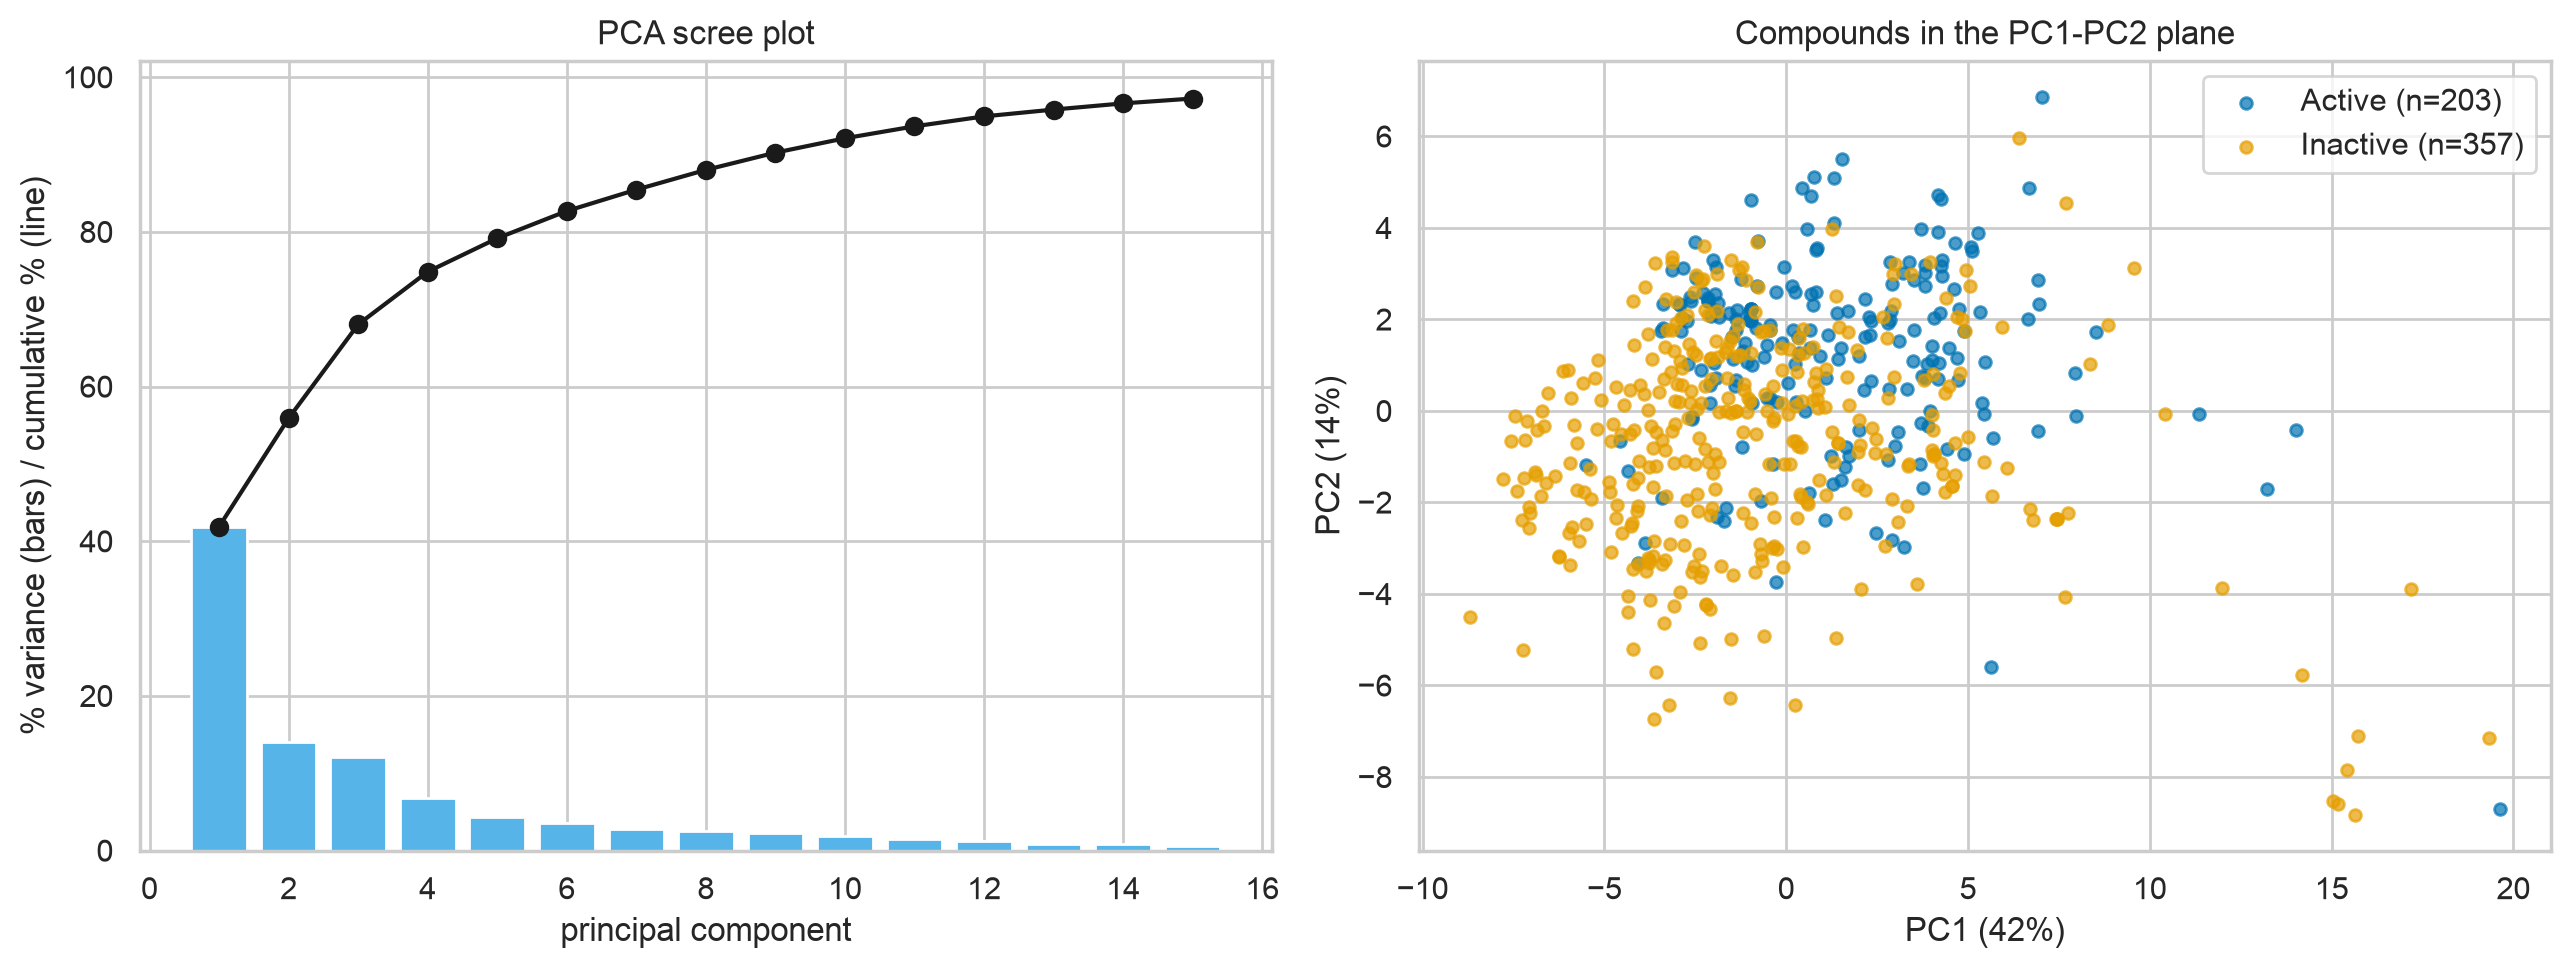

PC1+PC2 explain 56% of the variance; 9 PCs are needed for 90%.

Largest |loadings|:
                      PC1   PC2
Chi0                 0.23  0.03
NumValenceElectrons  0.23  0.02
HeavyAtomCount       0.23  0.06
Chi1                 0.23  0.08
LabuteASA            0.23  0.07
ExactMolWt           0.23  0.04


In [ ]:
pca = PCA(random_state=SEED).fit(Z)
scores = pca.transform(Z)
cum = np.cumsum(pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(range(1, 16), 100 * pca.explained_variance_ratio_[:15], color='#56B4E9')
axes[0].plot(range(1, 16), 100 * cum[:15], 'o-', color='k')
axes[0].set_xlabel('principal component'); axes[0].set_ylabel('% variance (bars) / cumulative % (line)')
axes[0].set_title('PCA scree plot')

for outcome, g in df.groupby('Outcome'):
    axes[1].scatter(scores[g.index, 0], scores[g.index, 1], s=18, alpha=.7,
                    color=CLASS_COLORS[outcome], label=f'{outcome} (n={len(g)})')
axes[1].set_xlabel(f'PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}%)')
axes[1].set_ylabel(f'PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)')
axes[1].set_title('Compounds in the PC1-PC2 plane'); axes[1].legend()
plt.tight_layout(); plt.show()

print(f'PC1+PC2 explain {100 * cum[1]:.0f}% of the variance; {np.searchsorted(cum, 0.90) + 1} PCs are needed for 90%.')
loadings = pd.DataFrame(pca.components_[:2].T, index=desc.columns, columns=['PC1', 'PC2'])
print('\nLargest |loadings|:')
print(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).head(6).round(2).to_string())

PC1 is a "molecular size" axis (all size, atom-count and surface-area descriptors load on it with the same sign).
PC2 contrasts lipophilicity and aromaticity (`MolLogP`, number of aromatic rings: positive) with polarity (`TPSA`, H-bond donors: negative).
Actives and inactives overlap strongly but are not identically distributed: actives concentrate at positive PC2 (lipophilic, aromatic)
and medium PC1, whereas inactives fill the small-molecule end (negative PC1) and the polar, large-molecule corner (negative PC2, large PC1).
The groups are not cleanly separated, which already tells us that unsupervised clusters will not be pure.

## 4. Clustering in Python

### 4.1 How the Colab hierarchical-clustering guide maps onto this dataset

The guide ("Definitive Guide to Hierarchical Clustering with Python and Scikit-Learn") follows a recipe that applies here
step by step; only the **features** change: in the guide each row is a customer described by a few numbers, here each row
is a molecule, so we first have to *turn molecules into numbers*.

| Step in the guide | In this notebook |
|---|---|
| Load the table with pandas | `pd.read_excel`, then RDKit parses the SMILES (§2) |
| Pre-process / engineer features | 43 RDKit descriptors, `StandardScaler` so that every descriptor has the same weight (§3) |
| Reduce dimensionality with PCA | PCA for visualisation (§3.1, §4.5); clustering itself uses the full standardised space |
| Plot a dendrogram, try linkage methods | `scipy.cluster.hierarchy.linkage` + `dendrogram` for `ward`, `complete`, `average`, `single` (§4.3) |
| Agglomerative clustering with scikit-learn | `AgglomerativeClustering(linkage='ward')`, checked against SciPy (§4.6) |
| Decide the number of clusters | silhouette, dendrogram height gaps, cluster sizes (§4.4) |

A second possible representation of a molecule is a **fingerprint** (a bit vector of its fragments) compared with the
**Tanimoto** distance. We evaluate both representations.

### 4.2 Two distance spaces

In [ ]:
# (a) Descriptor space: Euclidean distance between standardised descriptors  -> matrix Z
# (b) Fingerprint space: Morgan (ECFP4-like) bit vectors, Tanimoto distance
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [fp_gen.GetFingerprint(m) for m in df['mol']]

D_tani = np.array([1 - np.array(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps])
np.fill_diagonal(D_tani, 0)
cond_tani = squareform(D_tani, checks=False)       # condensed form expected by SciPy

off_diag = D_tani[np.triu_indices(n, 1)]
nn_sim = 1 - np.sort(D_tani + np.eye(n) * 9, axis=1)[:, 0]
print(f'mean pairwise Tanimoto similarity       : {1 - off_diag.mean():.2f}')
print(f'median nearest-neighbour similarity     : {np.median(nn_sim):.2f}')
print(f'compounds whose nearest neighbour has sim < 0.4: {(nn_sim < 0.4).mean():.0%}')

mean pairwise Tanimoto similarity       : 0.10
median nearest-neighbour similarity     : 0.45
compounds whose nearest neighbour has sim < 0.4: 42%


The compounds are a collection of unrelated drugs, so a typical molecule has no close analogue.
This anticipates that fingerprint-based clusters will be poorly defined.

### 4.3 Hierarchical clustering: linkage methods and dendrograms

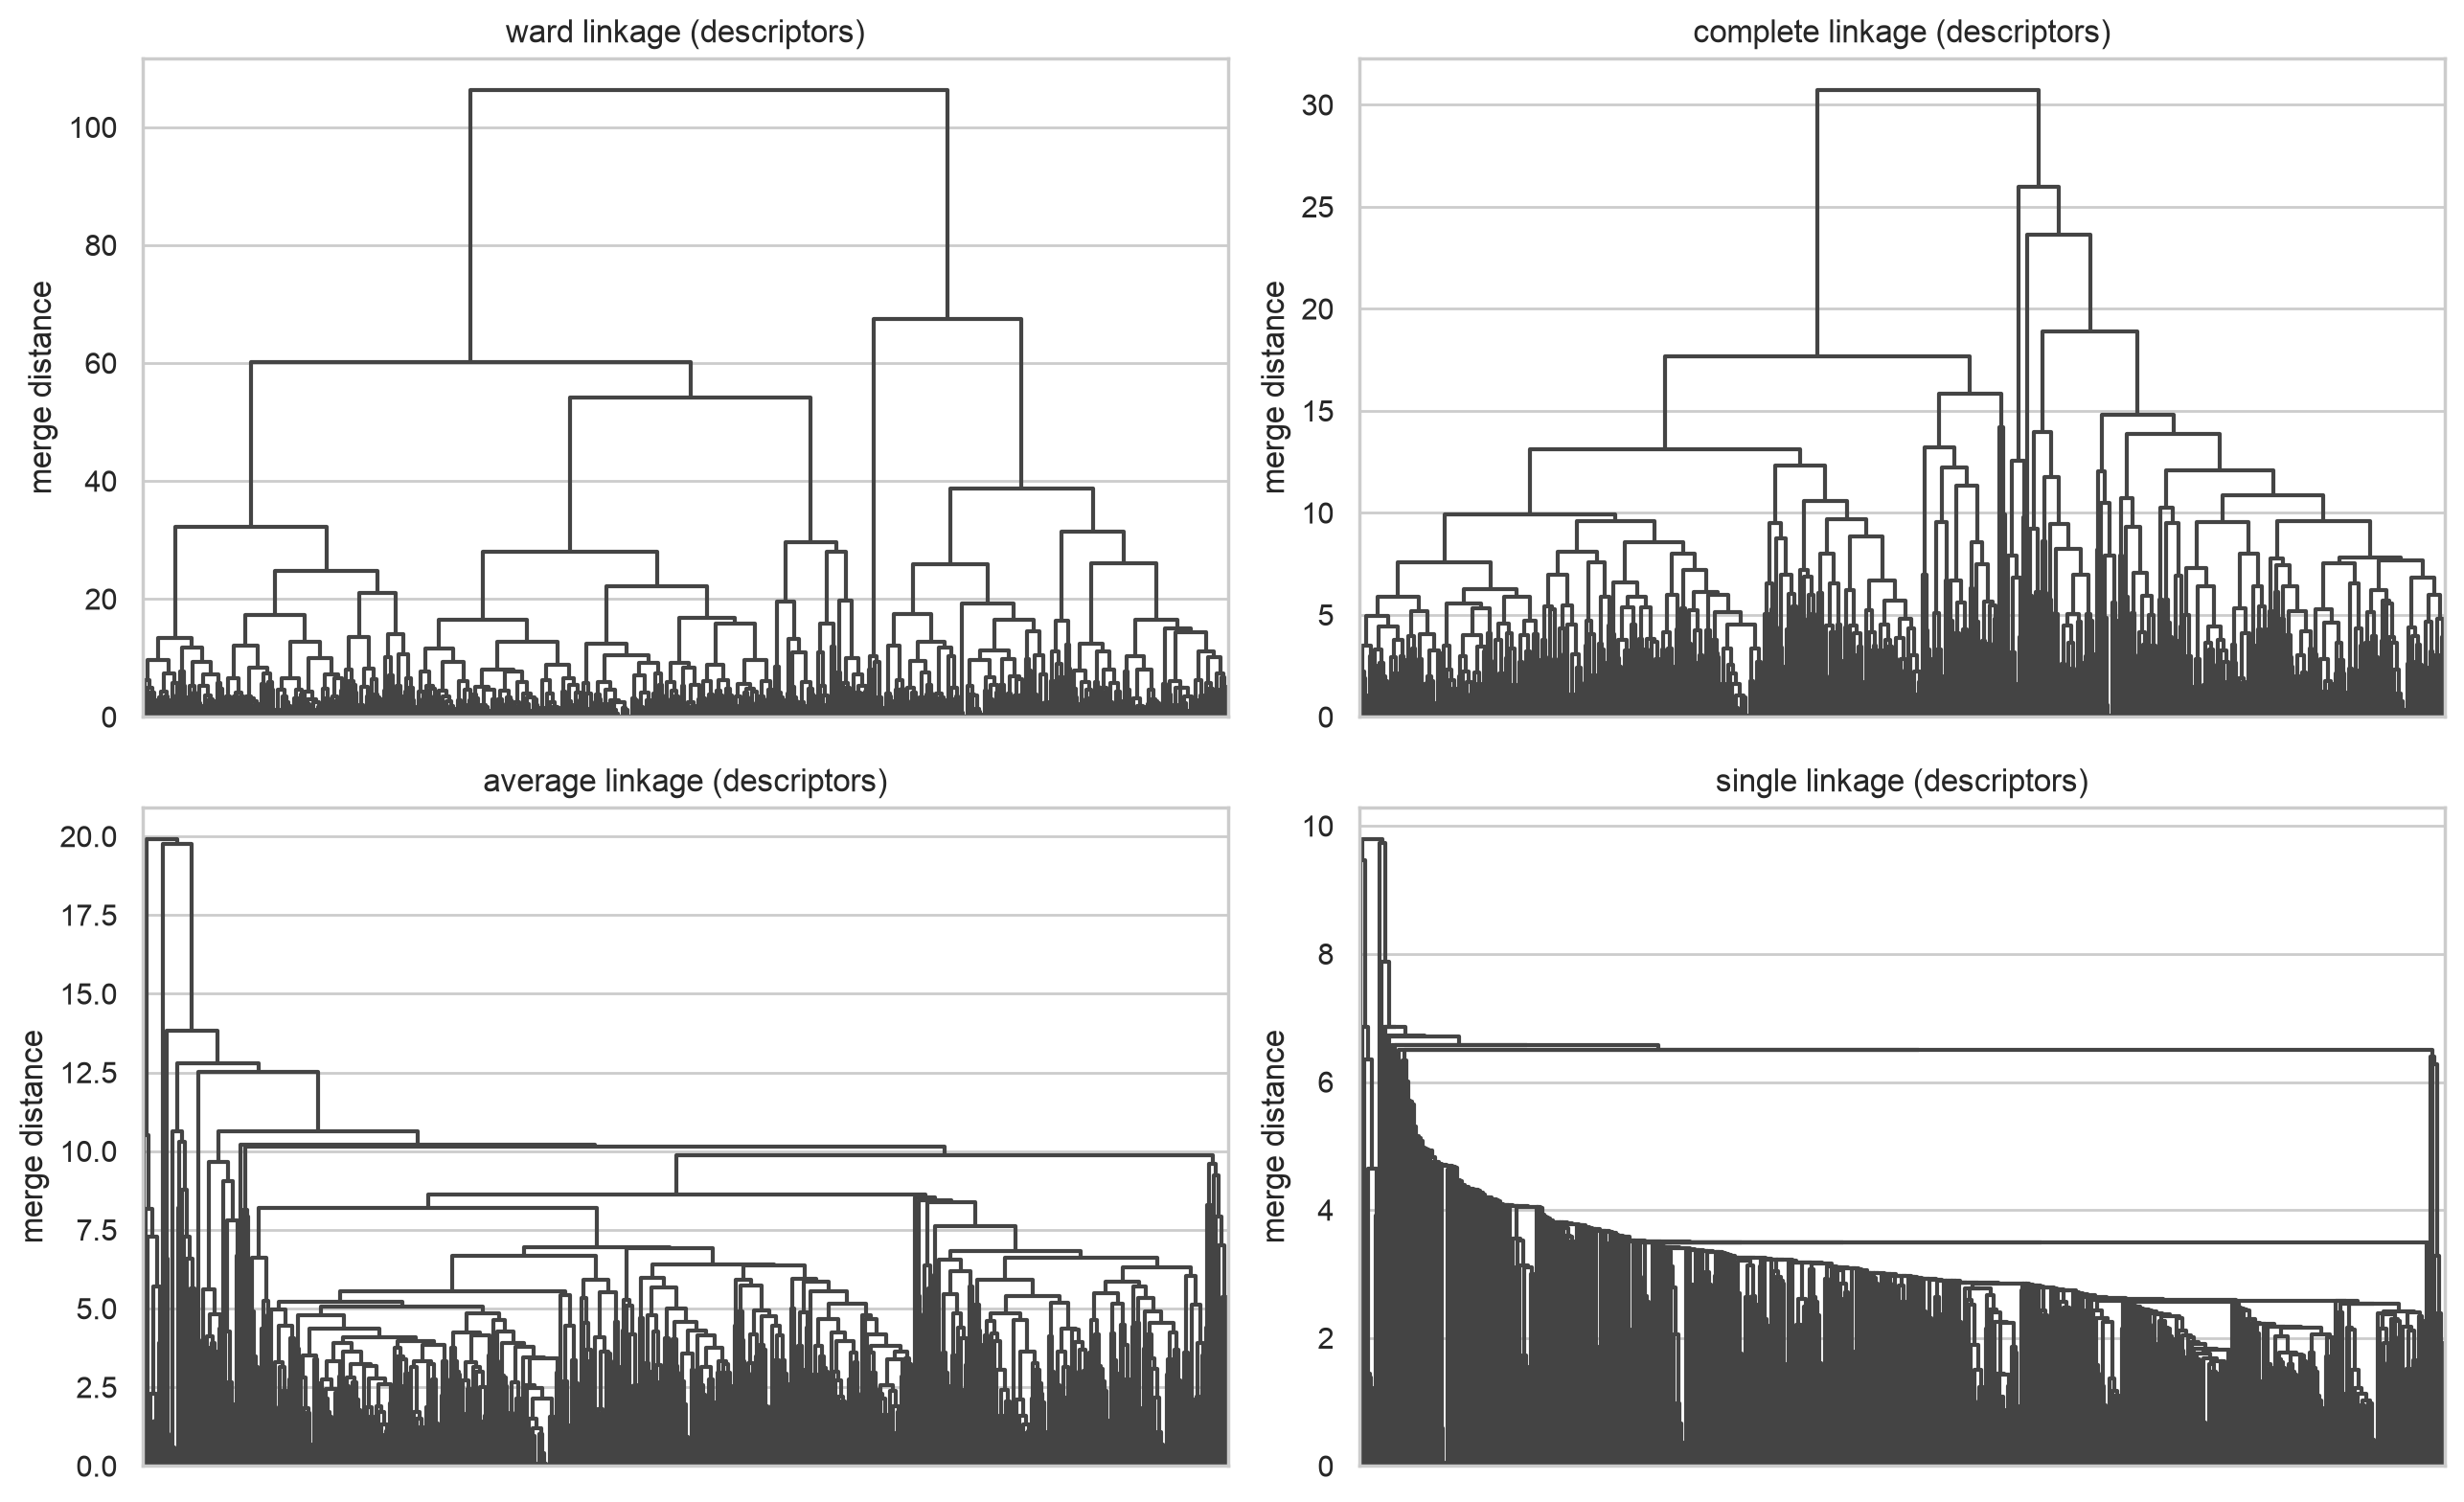

Cophenetic correlation (how faithfully the tree preserves the original distances):
ward-desc            0.440
complete-desc        0.452
average-desc         0.838
single-desc          0.783
complete-tanimoto    0.698
average-tanimoto     0.773
single-tanimoto      0.614


In [ ]:
link_desc = {m: linkage(Z, method=m) for m in ['ward', 'complete', 'average', 'single']}
# Ward requires Euclidean distances, so it is not applied to Tanimoto distances.
link_tani = {m: linkage(cond_tani, method=m) for m in ['complete', 'average', 'single']}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (meth, L) in zip(axes.ravel(), link_desc.items()):
    dendrogram(L, ax=ax, no_labels=True, color_threshold=0, above_threshold_color='#444')
    ax.set_title(f'{meth} linkage (descriptors)'); ax.set_ylabel('merge distance')
plt.tight_layout(); plt.show()

coph = pd.Series({**{f'{m}-desc': cophenet(L, pdist(Z))[0] for m, L in link_desc.items()},
                  **{f'{m}-tanimoto': cophenet(L, cond_tani)[0] for m, L in link_tani.items()}})
print('Cophenetic correlation (how faithfully the tree preserves the original distances):')
print(coph.round(3).to_string())

* **Ward** builds compact, balanced clusters: the tree has a few very tall branches at the top and then splits regularly.
* **Single** and **average** show the classical *chaining* effect: one long staircase that peels off a few outlying molecules one by one.
* **Complete** is in between.

A high cophenetic correlation (average, single) only says the tree is faithful to the distances; it does **not** mean the
clusters are useful, and chained trees can score high. Next we compare partitions with cluster-quality indices.

### 4.4 Comparing methods and choosing one

For each method we cut the model into *k* = 2 … 12 clusters and compute:

* the **silhouette** coefficient (−1…1; higher = compact and well separated clusters; < 0.25 means no substantial structure),
* the **size of the smallest and largest cluster**: an index can be inflated by a degenerate partition (one tiny outlier cluster
  + one giant cluster), so such partitions are flagged as *degenerate*,
* Calinski–Harabasz (higher is better) and Davies–Bouldin (lower is better) for the descriptor space.

Methods: Ward / complete / average / single linkage and k-means on descriptors; complete / average / single linkage on Tanimoto distances.
Butina (sphere-exclusion, the standard cheminformatics algorithm) does not take *k*, so it is reported separately.

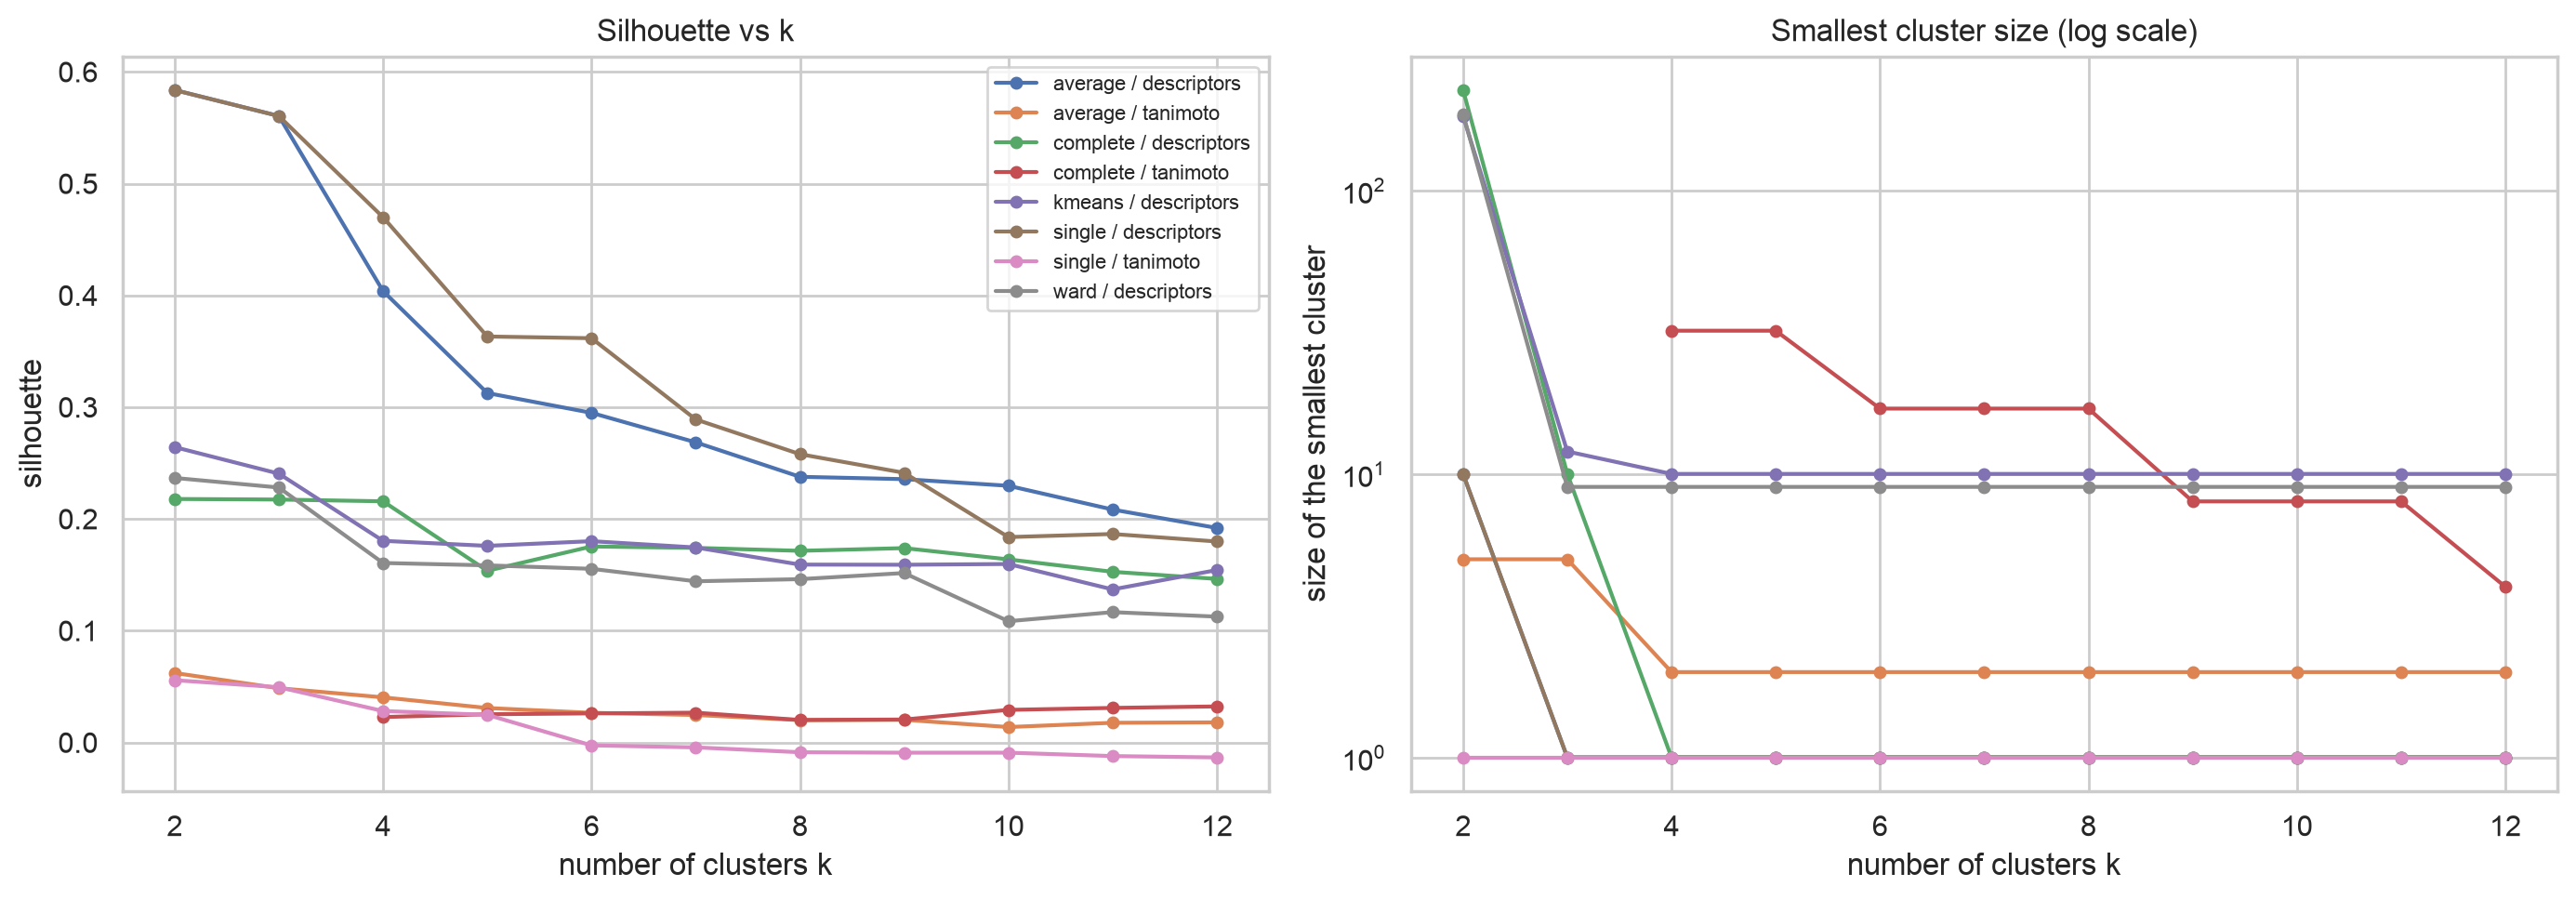

In [ ]:
K_RANGE = range(2, 13)

def evaluate(name, space, k, labels):
    """Quality indices for one partition."""
    sizes = np.bincount(labels)
    sizes = sizes[sizes > 0]
    if len(sizes) < 2:
        return None
    if space == 'descriptors':
        sil = silhouette_score(Z, labels)
        ch, db = calinski_harabasz_score(Z, labels), davies_bouldin_score(Z, labels)
    else:
        sil = silhouette_score(D_tani, labels, metric='precomputed')
        ch = db = np.nan
    return dict(method=name, space=space, k=k, n_clusters=len(sizes), silhouette=sil, CH=ch, DB=db,
                min_size=sizes.min(), max_frac=sizes.max() / n,
                ARI_vs_class=adjusted_rand_score(y, labels))

rows, labels_store = [], {}
for k in K_RANGE:
    candidates = {}
    for meth, L in link_desc.items():
        candidates[(f'{meth}', 'descriptors')] = fcluster(L, k, 'maxclust') - 1
    candidates[('kmeans', 'descriptors')] = KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)
    for meth, L in link_tani.items():
        candidates[(f'{meth}', 'tanimoto')] = fcluster(L, k, 'maxclust') - 1
    for (name, space), lab in candidates.items():
        r = evaluate(name, space, k, lab)
        if r:
            rows.append(r); labels_store[(name, space, k)] = lab

scan = pd.DataFrame(rows)
scan['label'] = scan['method'] + ' / ' + scan['space']
# a partition is degenerate when it has a cluster of < 1% of the compounds or one cluster holding > 80%
scan['degenerate'] = (scan['min_size'] < 0.01 * n) | (scan['max_frac'] > 0.80)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for lab, g in scan.groupby('label'):
    axes[0].plot(g['k'], g['silhouette'], 'o-', ms=4, label=lab)
    axes[1].plot(g['k'], g['min_size'], 'o-', ms=4, label=lab)
axes[0].set_xlabel('number of clusters k'); axes[0].set_ylabel('silhouette'); axes[0].set_title('Silhouette vs k')
axes[1].set_xlabel('number of clusters k'); axes[1].set_ylabel('size of the smallest cluster')
axes[1].set_yscale('log'); axes[1].set_title('Smallest cluster size (log scale)')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
valid = scan[~scan['degenerate']]
best = (valid.sort_values('silhouette', ascending=False).groupby('label').head(1)
             .sort_values('silhouette', ascending=False))
display(best[['label', 'k', 'silhouette', 'CH', 'DB', 'min_size', 'max_frac']].round(3).reset_index(drop=True))

print('Methods with NO non-degenerate partition:',
      sorted(set(scan['label']) - set(valid['label'])))
print('\nBest silhouette reached by the degenerate partitions (chaining / outlier peeling):')
display(scan[scan['degenerate']].sort_values('silhouette', ascending=False)
        .groupby('label').head(1)[['label', 'k', 'silhouette', 'min_size', 'max_frac']].round(3).head(5).reset_index(drop=True))

,label,k,silhouette,CH,DB,min_size,max_frac
0,kmeans / descriptors,2,0.264,194.932,1.502,183,0.673
1,ward / descriptors,2,0.237,171.299,1.596,186,0.668
2,complete / descriptors,2,0.218,168.714,1.656,226,0.596
3,complete / tanimoto,11,0.031,NaN,NaN,8,0.330


Methods with NO non-degenerate partition: ['average / descriptors', 'average / tanimoto', 'single / descriptors', 'single / tanimoto']

Best silhouette reached by the degenerate partitions (chaining / outlier peeling):


,label,k,silhouette,min_size,max_frac
0,average / descriptors,2,0.584,10,0.982
1,single / descriptors,2,0.584,10,0.982
2,complete / descriptors,4,0.216,1,0.596
3,average / tanimoto,2,0.062,5,0.991
4,single / tanimoto,2,0.056,1,0.998


In [ ]:
print('Values of k for which the partition is NOT degenerate:')
print(valid.groupby('label')['k'].apply(list).to_string())
print('\nAt k = 5, silhouette of the descriptor-space methods:')
print(scan.query("k == 5 and space == 'descriptors'")[['label', 'silhouette', 'min_size', 'max_frac']].round(3).to_string(index=False))

Values of k for which the partition is NOT degenerate:
label
complete / descriptors                                  [2, 3]
complete / tanimoto                 [4, 5, 6, 7, 8, 9, 10, 11]
kmeans / descriptors      [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
ward / descriptors        [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

At k = 5, silhouette of the descriptor-space methods:
                 label  silhouette  min_size  max_frac
    ward / descriptors       0.159         9     0.330
complete / descriptors       0.154         1     0.596
 average / descriptors       0.313         1     0.950
  single / descriptors       0.363         1     0.979
  kmeans / descriptors       0.176        10     0.338


In [ ]:
print('Butina clustering on Tanimoto distance (sphere exclusion, distance threshold t):')
lower_tri = [D_tani[i, j] for i in range(1, n) for j in range(i)]
for t in (0.5, 0.6, 0.7):
    cl = Butina.ClusterData(lower_tri, n, t, isDistData=True)
    sizes = sorted((len(c) for c in cl), reverse=True)
    print(f'  t={t}: {len(cl)} clusters, {sum(s == 1 for s in sizes)} singletons, largest sizes {sizes[:5]}')

Butina clustering on Tanimoto distance (sphere exclusion, distance threshold t):
  t=0.5: 381 clusters, 311 singletons, largest sizes [21, 16, 12, 11, 8]
  t=0.6: 323 clusters, 249 singletons, largest sizes [24, 21, 17, 14, 7]
  t=0.7: 240 clusters, 156 singletons, largest sizes [24, 21, 19, 16, 15]


**What the comparison shows**

* **Fingerprints / Tanimoto distance (any linkage) and Butina:** silhouettes are essentially zero and Butina produces hundreds of clusters,
  most of them singletons. A diverse set of unrelated drugs has no families of close analogues to find, so structural-similarity
  clustering is not informative here.
* **Single and average linkage on descriptors** have the *highest* silhouettes (up to 0.58), but only because they peel off a handful of outliers
  (smallest cluster of 1–10 compounds, one cluster holding > 95% of the data): the index is inflated by a useless partition.
  **Complete linkage** is acceptable only for *k* = 2–3 and then also starts isolating single compounds.
* **Ward and k-means on the standardised descriptors** are the only methods that stay balanced for every *k* from 2 to 12.
  K-means has a slightly higher silhouette (by about 0.02–0.03), but both are low in absolute terms (≲ 0.26): the chemical
  space is a *continuum*, not a set of well-separated groups, so clusters are best read as regions of property space.

**Chosen method: Ward hierarchical clustering on the standardised descriptors.** Reasons: (1) it is close to k-means on every index
(silhouette within ~0.03) and keeps balanced clusters for all *k*; (2) it is deterministic (no random initialisation) and nested, so one dendrogram serves for every *k*;
(3) the dendrogram gives a principled way to choose *k*; (4) the same algorithm exists in R (`hclust(method = "ward.D2")`),
so the Python and R halves of this report can be checked against each other (§8).

**Choosing k.** Silhouette alone prefers *k* = 2, which is just a "small molecules / large molecules" split.
We therefore also look at how long each *k* survives in the dendrogram (the gap between consecutive merge heights).

In [ ]:
L_ward = link_desc['ward']
heights = L_ward[::-1, 2]                      # merge heights, tallest first: heights[0] is the last merge
gap_table = pd.DataFrame({
    'k': np.arange(2, 11),
    'silhouette (Ward)': [scan.query("label == 'ward / descriptors' and k == @k")['silhouette'].iloc[0] for k in range(2, 11)],
    'height range where k clusters exist': [f'{heights[k - 1]:.1f} - {heights[k - 2]:.1f}' for k in range(2, 11)],
    'plateau width': [heights[k - 2] - heights[k - 1] for k in range(2, 11)],
    'smallest cluster': [scan.query("label == 'ward / descriptors' and k == @k")['min_size'].iloc[0] for k in range(2, 11)],
}).set_index('k')
display(gap_table.round(3))

,silhouette (Ward),height range where k clusters exist,plateau width,smallest cluster
k,,,,
2,0.237,67.5 - 106.4,38.880,186
3,0.228,60.1 - 67.5,7.345,9
4,0.161,54.1 - 60.1,5.998,9
5,0.159,38.8 - 54.1,15.344,9
6,0.155,32.3 - 38.8,6.526,9
7,0.144,31.4 - 32.3,0.885,9
8,0.146,29.7 - 31.4,1.691,9
9,0.152,28.1 - 29.7,1.599,9
10,0.109,28.0 - 28.1,0.129,9


After the trivial *k* = 2 the **widest plateau is at *k* = 5**: five clusters survive over a much wider range of
heights than 3, 4 or 6. Its silhouette (0.16) is the same as that of *k* = 4 and 6, so moving to 5 clusters costs nothing in quality.
We therefore take **K = 5** and check how stable it is.

In [ ]:
K = 5
raw_labels = fcluster(L_ward, K, 'maxclust')

# Relabel the clusters 1..K by increasing mean logP so the labels are meaningful and reproducible
order = df.groupby(raw_labels)['logP'].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order, start=1)}
df['cluster'] = [relabel[c] for c in raw_labels]

# --- stability: re-cluster 50 random 80% subsamples and compare with the full-data clustering
rng = np.random.default_rng(SEED)
ari_sub = []
for _ in range(50):
    idx = rng.choice(n, int(0.8 * n), replace=False)
    sub = fcluster(linkage(Z[idx], 'ward'), K, 'maxclust')
    ari_sub.append(adjusted_rand_score(df['cluster'].to_numpy()[idx], sub))

km_labels = labels_store[('kmeans', 'descriptors', K)]
print(f'Stability (adjusted Rand index, 50 subsamples of 80%): mean {np.mean(ari_sub):.2f}, min {np.min(ari_sub):.2f}')
print(f'Agreement Ward vs k-means (ARI)                     : {adjusted_rand_score(df["cluster"], km_labels):.2f}')
print(f'Silhouette of the chosen clustering                 : {silhouette_score(Z, df["cluster"]):.3f}')
print(f'Cophenetic correlation of the Ward tree             : {coph["ward-desc"]:.3f}')

Stability (adjusted Rand index, 50 subsamples of 80%): mean 0.65, min 0.39
Agreement Ward vs k-means (ARI)                     : 0.64
Silhouette of the chosen clustering                 : 0.159
Cophenetic correlation of the Ward tree             : 0.440


The stability is **moderate** (mean ARI ≈ 0.65 on 80% subsamples): the borders between the large clusters move when the data change slightly,
while the small, very distinctive cluster is always recovered. Ward and k-means agree only partly (ARI ≈ 0.64), as expected for
data without sharp group boundaries.

### 4.5 The chosen clusters

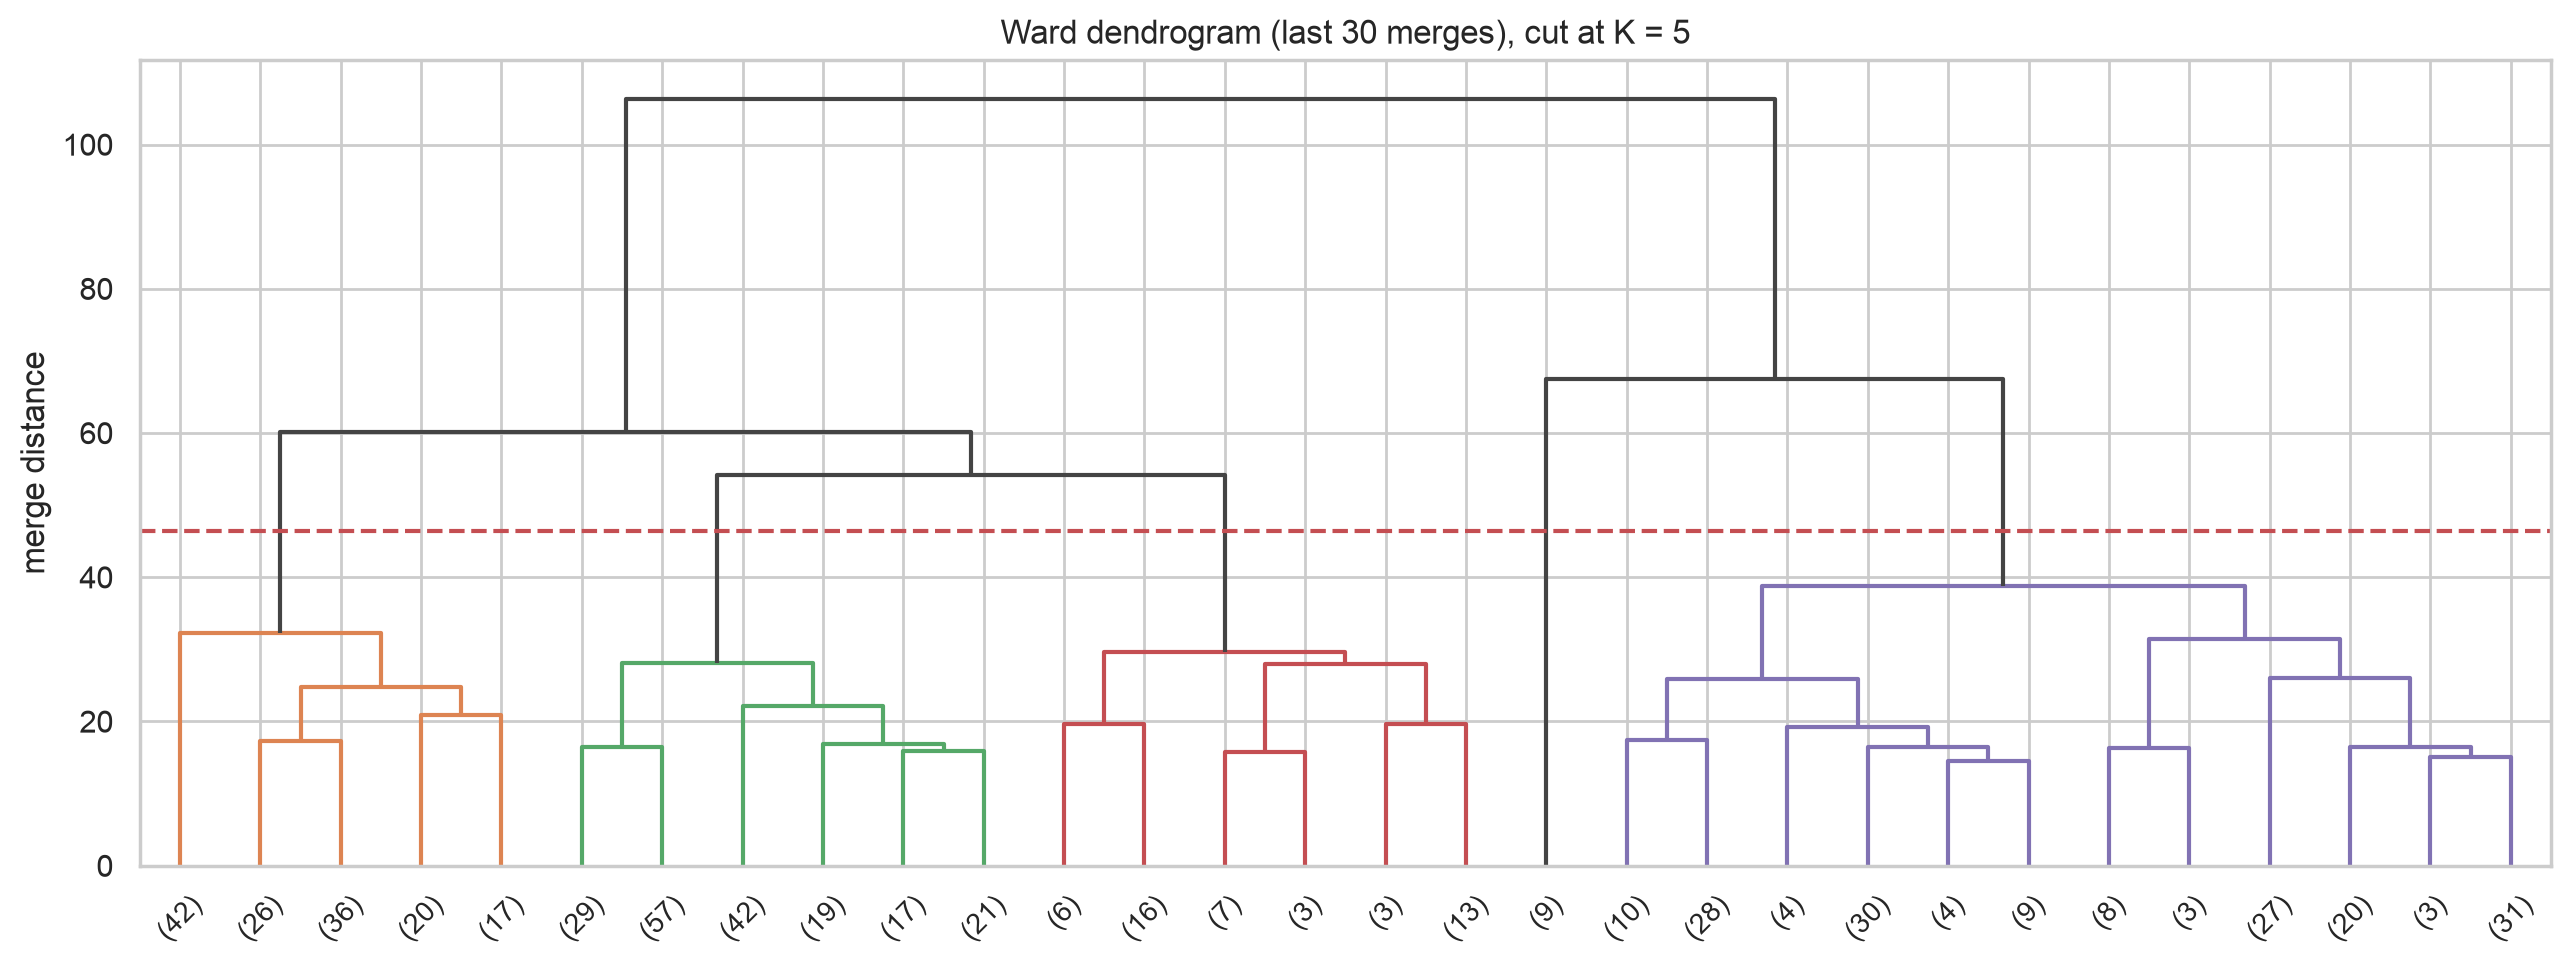

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(L_ward, truncate_mode='lastp', p=30, ax=ax, show_leaf_counts=True,
           color_threshold=(heights[K - 1] + heights[K - 2]) / 2, above_threshold_color='#444')
ax.axhline((heights[K - 1] + heights[K - 2]) / 2, ls='--', color='r')
ax.set_title(f'Ward dendrogram (last 30 merges), cut at K = {K}'); ax.set_ylabel('merge distance')
plt.tight_layout(); plt.show()

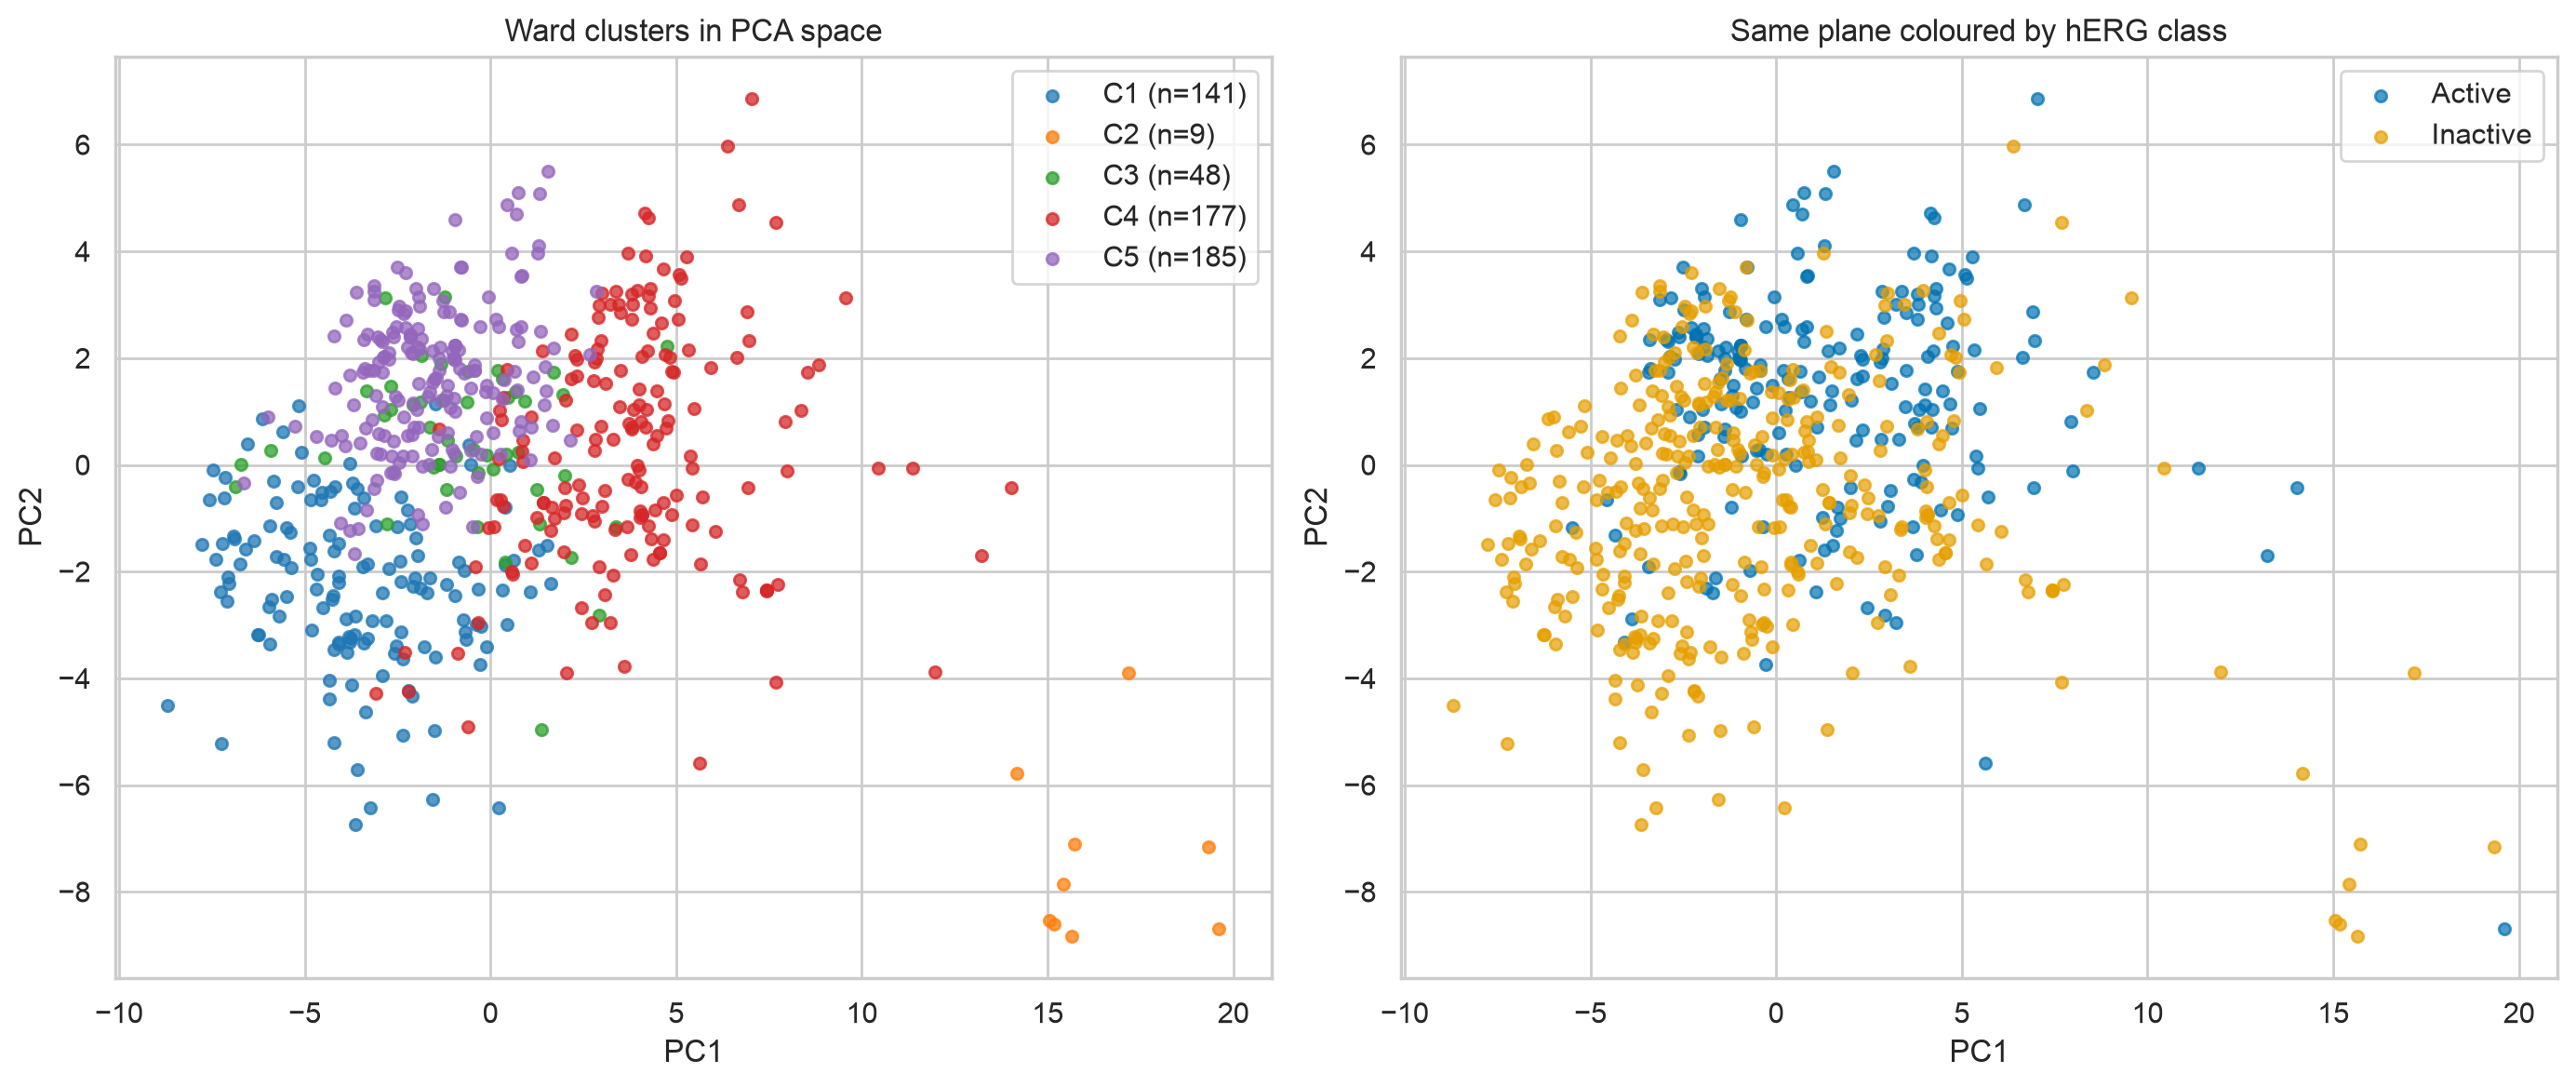

In [ ]:
palette = sns.color_palette('tab10', K)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for c in range(1, K + 1):
    idx = df.index[df['cluster'] == c]
    axes[0].scatter(scores[idx, 0], scores[idx, 1], s=20, alpha=.75, color=palette[c - 1],
                    label=f'C{c} (n={len(idx)})')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2'); axes[0].set_title('Ward clusters in PCA space'); axes[0].legend()

for outcome, g in df.groupby('Outcome'):
    axes[1].scatter(scores[g.index, 0], scores[g.index, 1], s=20, alpha=.7, color=CLASS_COLORS[outcome], label=outcome)
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].set_title('Same plane coloured by hERG class'); axes[1].legend()
plt.tight_layout(); plt.show()

,n,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumAromaticRings,NumRotatableBonds,FractionCSP3
cluster,,,,,,,,,
1,141,236.25,1.19,68.62,1.87,3.62,0.99,4.13,0.45
2,9,757.07,2.23,194.95,4.56,14.22,0.00,8.11,0.91
3,48,317.34,2.59,51.55,1.08,3.56,0.79,2.33,0.66
4,177,445.84,3.63,83.13,1.61,5.06,2.47,7.08,0.36
5,185,310.42,3.91,35.68,0.83,2.54,2.15,3.76,0.31


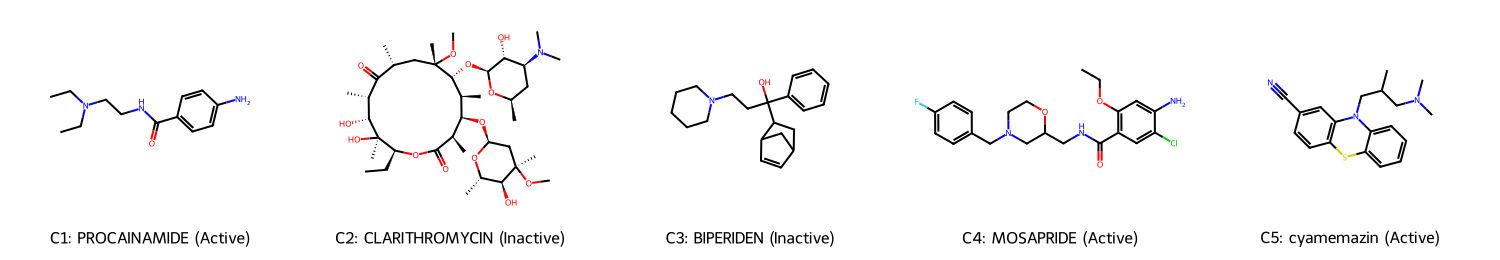

In [ ]:
profile_cols = ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumAromaticRings', 'NumRotatableBonds', 'FractionCSP3']
profile = desc.groupby(df['cluster'])[profile_cols].mean()
profile.insert(0, 'n', df['cluster'].value_counts().sort_index())
display(profile.round(2))

# Medoid-like representative: compound closest to the cluster centroid
reps, legends = [], []
for c in range(1, K + 1):
    idx = df.index[df['cluster'] == c]
    centroid = Z[idx].mean(axis=0)
    i = idx[np.argmin(((Z[idx] - centroid) ** 2).sum(axis=1))]
    reps.append(df.loc[i, 'mol']); legends.append(f"C{c}: {df.loc[i, 'Name']} ({df.loc[i, 'Outcome']})")
Draw.MolsToGridImage(reps, molsPerRow=5, subImgSize=(300, 260), legends=legends)

The clusters are property-based and easy to read (they are numbered by increasing mean logP):

* **C1** (141): small, polar molecules (mean MW 236, logP 1.2, about one aromatic ring);
* **C2** (9): very large, very polar, non-aromatic molecules — the macrolide antibiotics and FK506 (erythromycin, clarithromycin, josamycin, ...);
* **C3** (48): rigid, saturated polycycles with little aromaticity (steroids, tropane and morphinan alkaloids, fluoroquinolones), intermediate logP;
* **C4** (177): large, aromatic, drug-like molecules (mean MW 446, ≈ 2.5 aromatic rings, TPSA 83);
* **C5** (185): compact, lipophilic, aromatic molecules with very low polarity (mean logP 3.9, TPSA 36, < 1 H-bond donor).

### 4.6 Silhouette plot and cross-check with scikit-learn

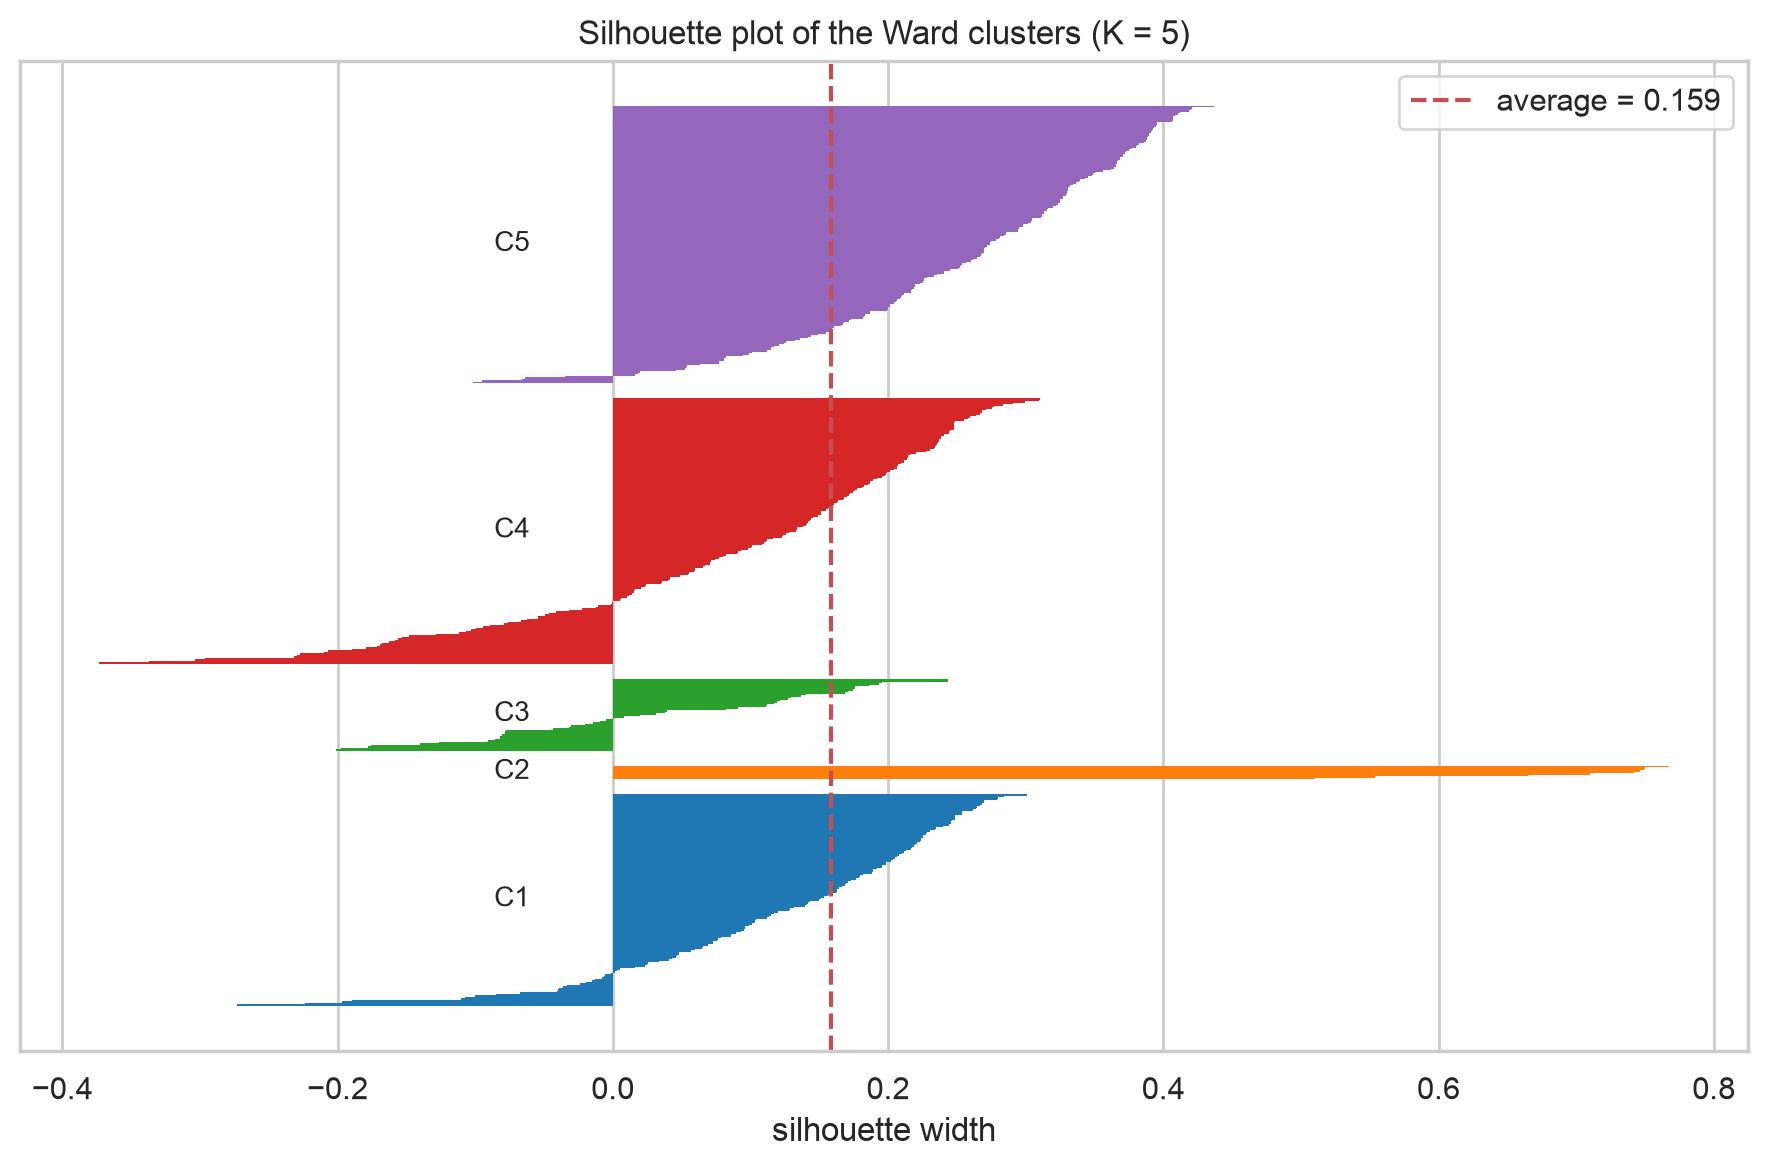

Share of compounds with negative silhouette (probably assigned to the wrong cluster): 16%
cluster
1    0.124
2    0.688
3    0.032
4    0.091
5    0.257

AgglomerativeClustering(ward) vs SciPy Ward -> ARI = 1.0


In [ ]:
sil = silhouette_samples(Z, df['cluster'])
fig, ax = plt.subplots(figsize=(9, 6))
y_lower = 0
for c in range(1, K + 1):
    s = np.sort(sil[df['cluster'] == c])
    ax.barh(np.arange(y_lower, y_lower + len(s)), s, height=1.0, color=palette[c - 1], edgecolor='none')
    ax.text(-0.06, y_lower + len(s) / 2, f'C{c}', va='center', ha='right', fontsize=10)
    y_lower += len(s) + 10
ax.axvline(sil.mean(), color='r', ls='--', label=f'average = {sil.mean():.3f}')
ax.set_yticks([]); ax.set_xlabel('silhouette width'); ax.set_title('Silhouette plot of the Ward clusters (K = 5)')
ax.legend(); plt.tight_layout(); plt.show()

print('Share of compounds with negative silhouette (probably assigned to the wrong cluster):'
      f' {(sil < 0).mean():.0%}')
print(pd.Series(sil).groupby(df['cluster']).mean().round(3).rename('mean silhouette per cluster').to_string())

# The recipe from the Colab guide: sklearn's AgglomerativeClustering gives the same Ward clusters as SciPy
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Z)
print('\nAgglomerativeClustering(ward) vs SciPy Ward -> ARI =',
      round(adjusted_rand_score(agg.labels_, df['cluster']), 3))

The average silhouette (≈ 0.16) confirms that the clusters are **soft**: 16% of the compounds have a negative width, most of them in
C4 (the broad "large drug-like" cluster that borders C3 and C5). Only the macrolide cluster C2 is really well separated (mean width ≈ 0.7). This is expected for a continuum of drug-like properties and should be kept in mind when
interpreting the active percentages below.

## 5. Active percentage per cluster

In [ ]:
ct = pd.crosstab(df['cluster'], df['Outcome'])[['Inactive', 'Active']]
res = ct.assign(n=ct.sum(axis=1))
res['active_%'] = 100 * res['Active'] / res['n']
ci = [stats.binomtest(int(a), int(m)).proportion_ci(method='wilson') for a, m in zip(res['Active'], res['n'])]
res['CI95_low_%'] = [100 * c.low for c in ci]
res['CI95_high_%'] = [100 * c.high for c in ci]

# one-vs-rest Fisher exact test for each cluster, Benjamini-Hochberg corrected
overall_active = ct['Active'].sum(), ct['Inactive'].sum()
p_vals = []
for c in res.index:
    table = [[res.loc[c, 'Active'], res.loc[c, 'Inactive']],
             [overall_active[0] - res.loc[c, 'Active'], overall_active[1] - res.loc[c, 'Inactive']]]
    p_vals.append(stats.fisher_exact(table)[1])
res['p (cluster vs rest)'] = p_vals
res['p_BH'] = stats.false_discovery_control(p_vals)
res.index = [f'C{c}' for c in res.index]
display(res.round({'active_%': 1, 'CI95_low_%': 1, 'CI95_high_%': 1, 'p (cluster vs rest)': 4, 'p_BH': 4}))

chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
overall_pct = 100 * y.mean()
print(f'Overall active percentage: {overall_pct:.1f}%')
print(f'Chi-square test of independence (cluster x class): chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.2g}, Cramer V = {cramers_v:.2f}')
print(f'Adjusted Rand index between clusters and Class: {adjusted_rand_score(y, df["cluster"]):.3f}')

Outcome,Inactive,Active,n,active_%,CI95_low_%,CI95_high_%,p (cluster vs rest),p_BH
C1,124,17,141,12.1,7.7,18.5,0.0000,0.0000
C2,8,1,9,11.1,2.0,43.5,0.1662,0.2077
C3,35,13,48,27.1,16.6,41.0,0.2090,0.2090
C4,91,86,177,48.6,41.3,55.9,0.0000,0.0001
C5,99,86,185,46.5,39.4,53.7,0.0005,0.0009


Overall active percentage: 36.2%
Chi-square test of independence (cluster x class): chi2 = 60.0, dof = 4, p = 2.9e-12, Cramer V = 0.33
Adjusted Rand index between clusters and Class: 0.032


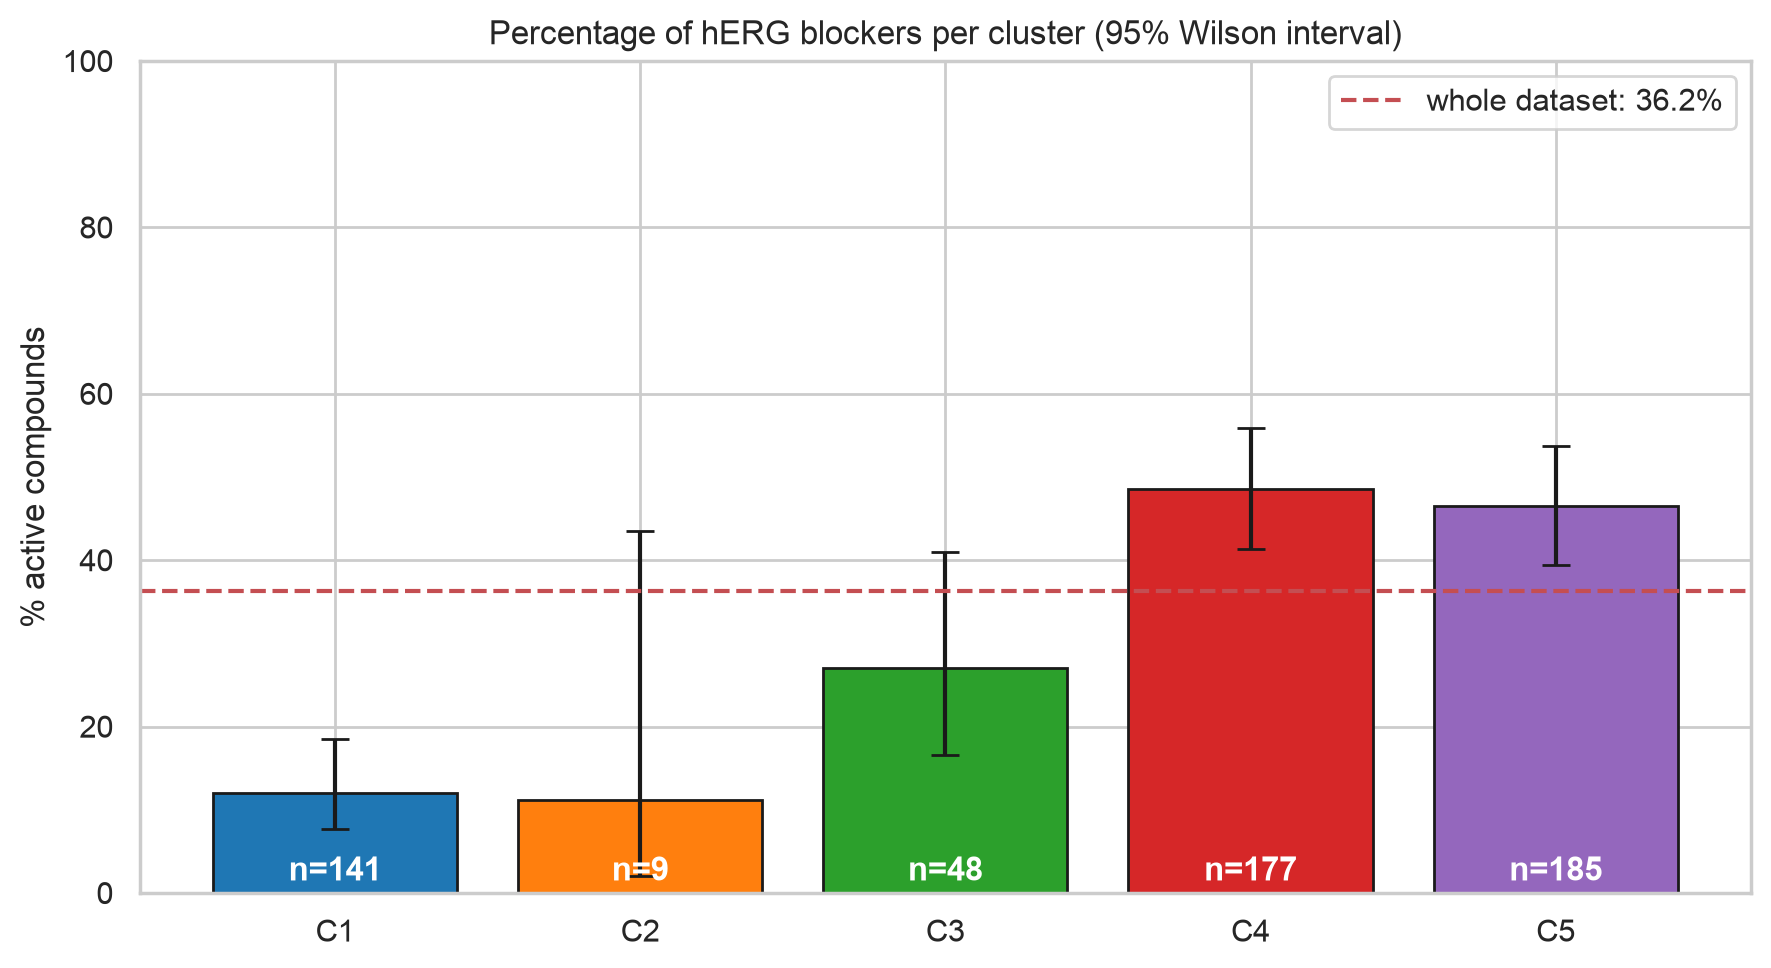

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(K)
err = np.vstack([res['active_%'] - res['CI95_low_%'], res['CI95_high_%'] - res['active_%']])
ax.bar(x, res['active_%'], yerr=err, capsize=5, color=palette, edgecolor='k')
ax.axhline(overall_pct, color='r', ls='--', label=f'whole dataset: {overall_pct:.1f}%')
for xi, (pct, m) in enumerate(zip(res['active_%'], res['n'])):
    ax.text(xi, 1.5, f'n={m}', ha='center', color='w', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(res.index); ax.set_ylabel('% active compounds'); ax.set_ylim(0, 100)
ax.set_title('Percentage of hERG blockers per cluster (95% Wilson interval)'); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.** The overall active rate is 36%. It differs strongly between clusters (chi-square p ≈ 3·10⁻¹², Cramér's V ≈ 0.33):
**C4 (49%) and C5 (47%)**, the lipophilic aromatic clusters, are enriched in blockers; **C1 (12%)**, the small polar molecules, is strongly depleted;
the intermediate C3 (27%) is not significantly different from the average after correction. C2 (macrolides) has 1 active out of 9 (11%), but with
only 9 compounds the interval is wide (2–44%), so no conclusion can be drawn for it. This follows the known hERG picture: blockers tend to be
lipophilic, aromatic and basic; small polar molecules rarely block the channel.

The clusters were built **without** using the labels. They are informative regions of property space, not a classifier: the adjusted Rand
index between clusters and class is only ≈ 0.03, because even in the best clusters about half of the compounds are inactive.

## 6. logP: actives vs inactives

`logP` is the Wildman–Crippen estimate (`Descriptors.MolLogP`) of the neutral molecule. We use non-parametric tests
(Mann–Whitney U, Kruskal–Wallis) because logP is not normally distributed within the groups.

In [ ]:
act = df.loc[df['Class'] == 1, 'logP']
ina = df.loc[df['Class'] == 0, 'logP']
u, p_mw = stats.mannwhitneyu(act, ina, alternative='two-sided')
pooled_sd = np.sqrt(((len(act) - 1) * act.var() + (len(ina) - 1) * ina.var()) / (len(act) + len(ina) - 2))
cohen_d = (act.mean() - ina.mean()) / pooled_sd
auc = roc_auc_score(df['Class'], df['logP'])

summary = df.groupby('Outcome')['logP'].describe()[['count', 'mean', 'std', '25%', '50%', '75%']]
display(summary.round(2))
print(f'Mann-Whitney U = {u:.0f}, p = {p_mw:.2g}')
print(f'Cohen d = {cohen_d:.2f} (difference of means / pooled SD)')
print(f'AUC of logP alone as a classifier = {auc:.2f}  (0.5 = chance)')

,count,mean,std,25%,50%,75%
Outcome,,,,,,
Active,203.0,3.86,1.63,2.85,3.96,4.82
Inactive,357.0,2.50,1.82,1.33,2.52,3.77


Mann-Whitney U = 51834, p = 2.4e-17
Cohen d = 0.78 (difference of means / pooled SD)
AUC of logP alone as a classifier = 0.72  (0.5 = chance)


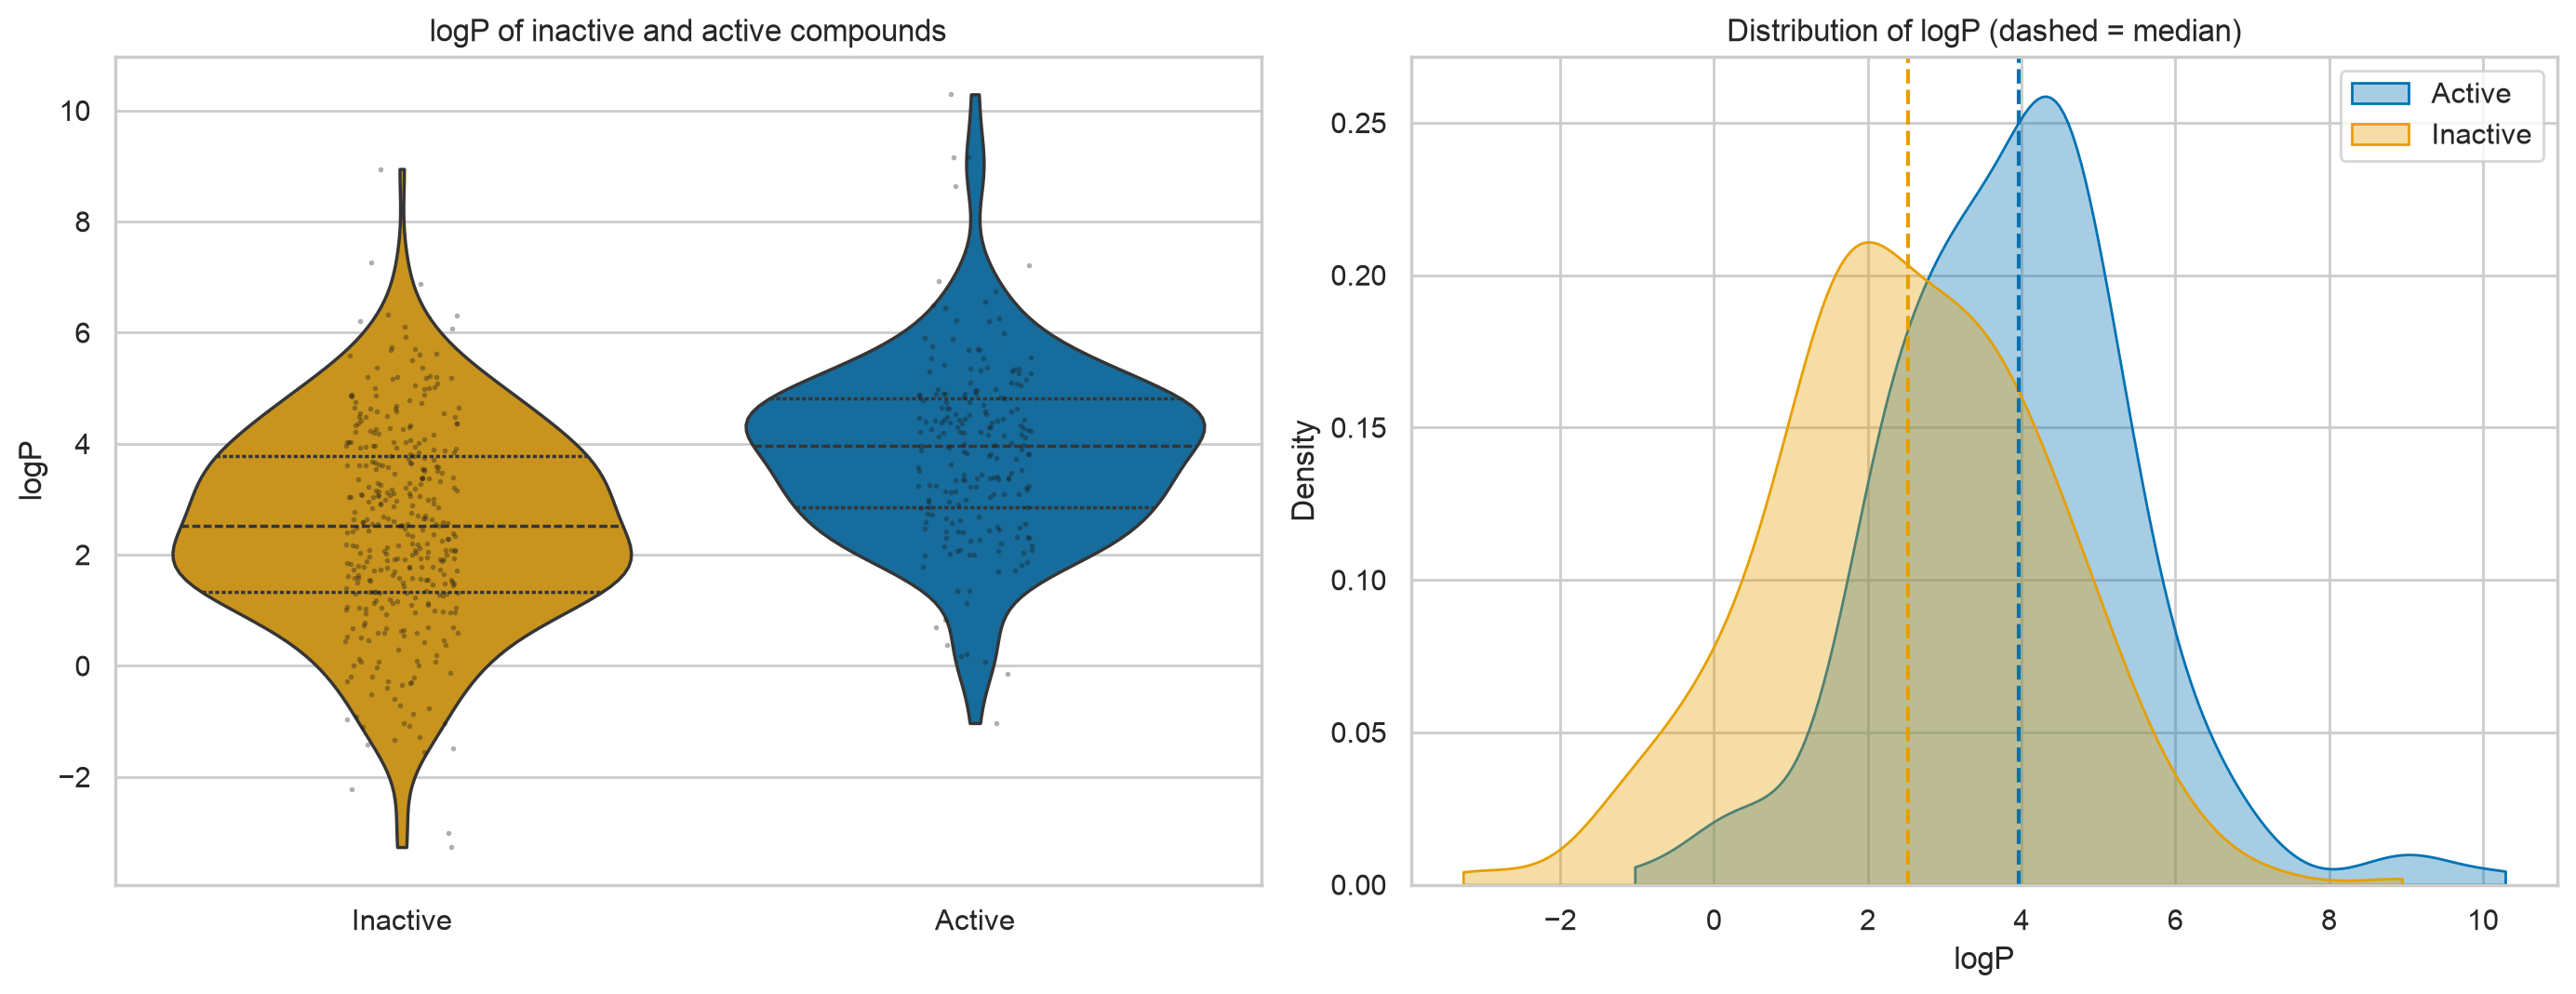

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.violinplot(data=df, x='Outcome', y='logP', order=['Inactive', 'Active'], palette=CLASS_COLORS,
               inner='quartile', cut=0, ax=axes[0])
sns.stripplot(data=df, x='Outcome', y='logP', order=['Inactive', 'Active'], color='k', size=2, alpha=.35, ax=axes[0])
axes[0].set_title('logP of inactive and active compounds'); axes[0].set_xlabel('')

for outcome, g in df.groupby('Outcome'):
    sns.kdeplot(g['logP'], ax=axes[1], color=CLASS_COLORS[outcome], fill=True, alpha=.35, label=outcome, cut=0)
    axes[1].axvline(g['logP'].median(), color=CLASS_COLORS[outcome], ls='--')
axes[1].set_title('Distribution of logP (dashed = median)'); axes[1].legend()
plt.tight_layout(); plt.show()

### 6.1 logP in each cluster

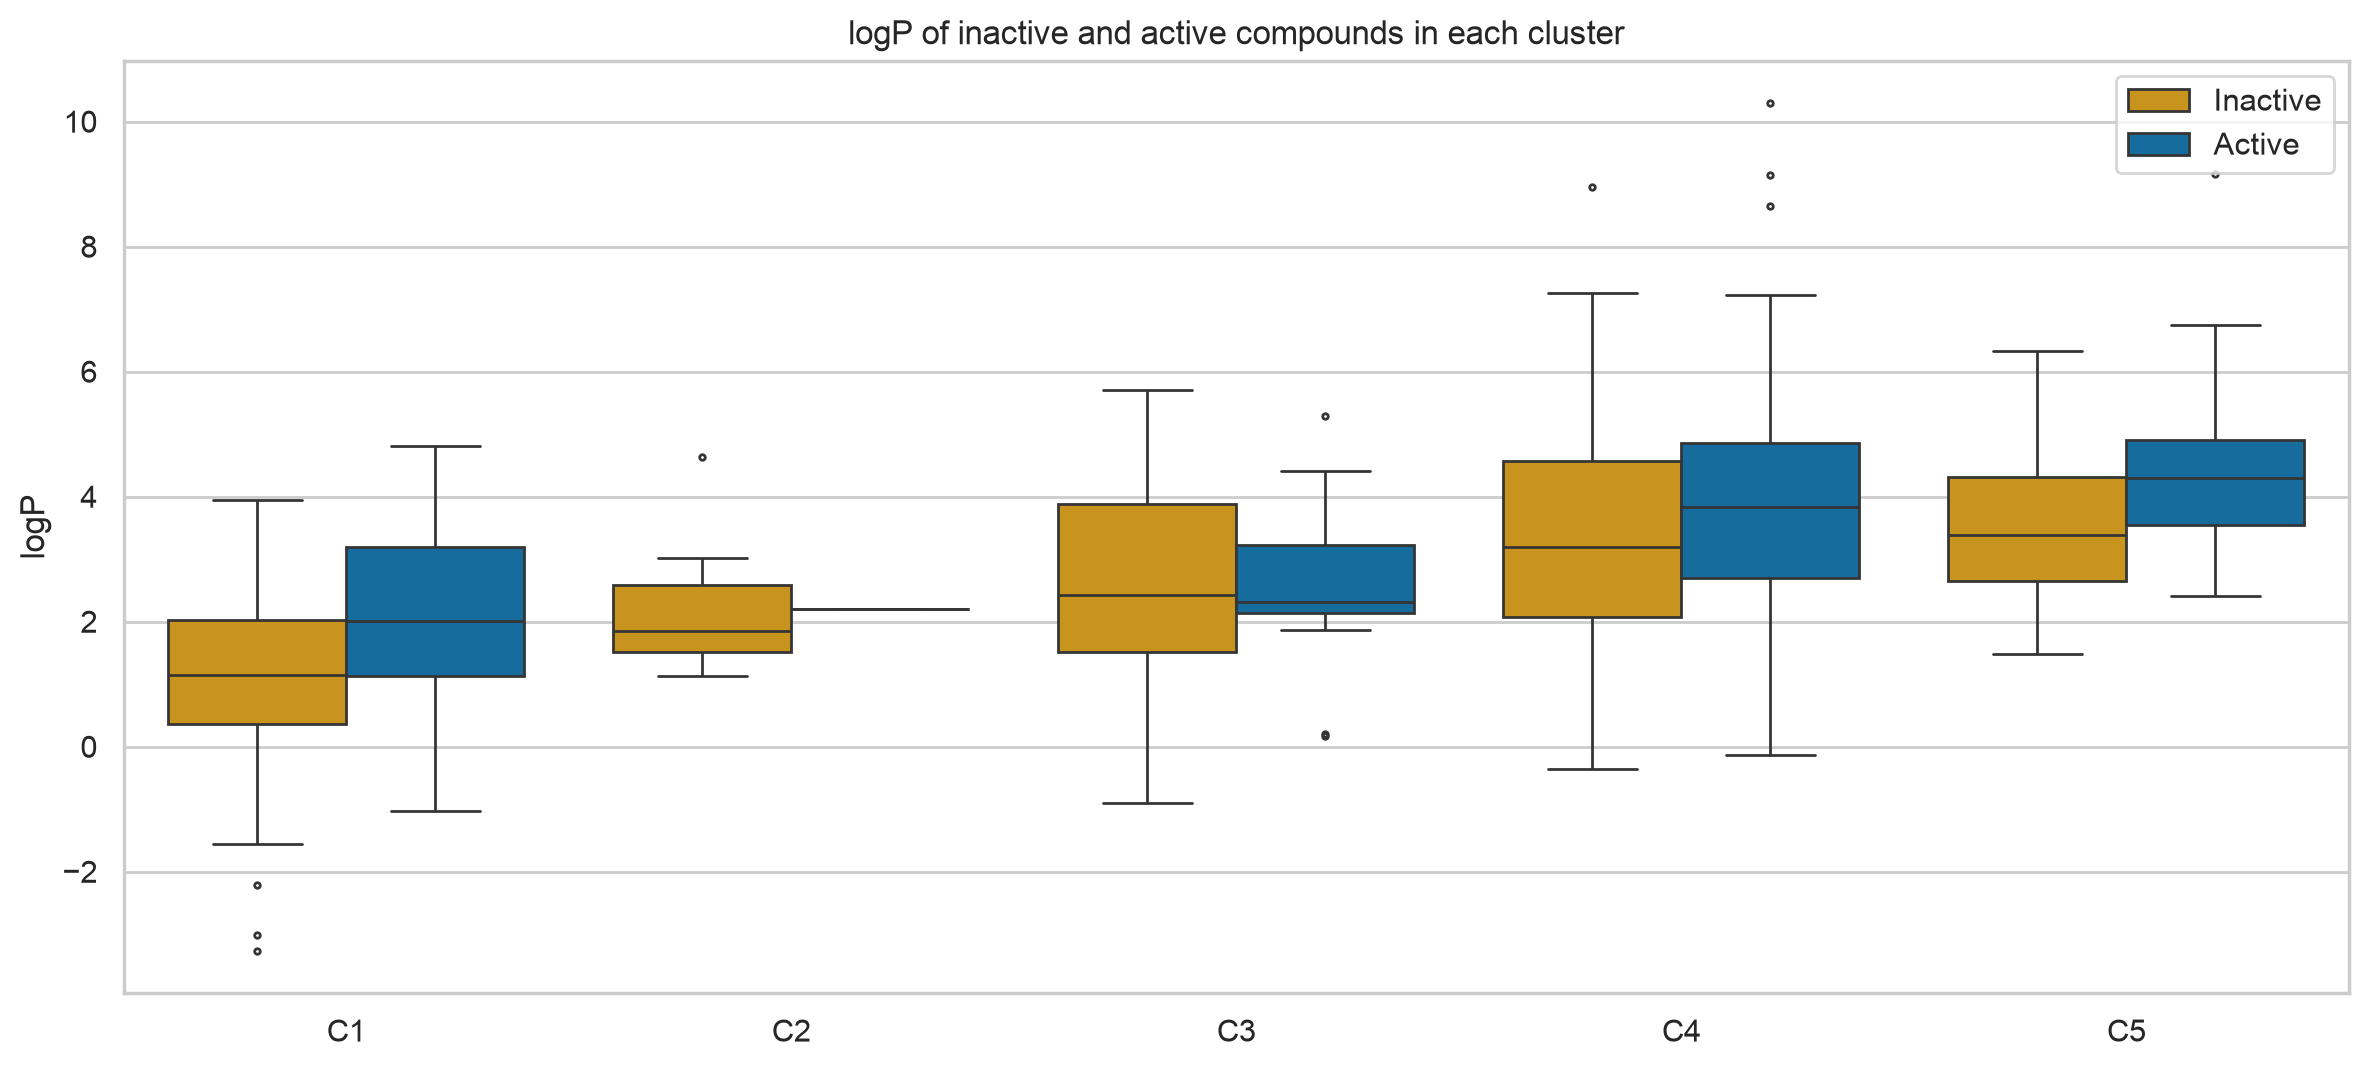

,n_active,n_inactive,median_active,median_inactive,delta_median,p_value,p_BH
cluster,,,,,,,
C1,17,124,2.002,1.146,0.857,0.022,0.036
C2,1,8,2.210,1.847,0.363,NaN,NaN
C3,13,35,2.318,2.421,-0.102,0.835,0.835
C4,86,91,3.835,3.202,0.633,0.027,0.036
C5,86,99,4.302,3.387,0.915,0.000,0.000


Kruskal-Wallis, logP across the 5 clusters: H = 209.9, p = 2.7e-44


In [ ]:
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=df, x='cluster', y='logP', hue='Outcome', hue_order=['Inactive', 'Active'], palette=CLASS_COLORS,
            fliersize=2, ax=ax)
ax.set_xticklabels([f'C{c}' for c in range(1, K + 1)]); ax.set_xlabel('')
ax.set_title('logP of inactive and active compounds in each cluster'); ax.legend(title='')
plt.tight_layout(); plt.show()

rows = []
for c in range(1, K + 1):
    a = df.loc[(df.cluster == c) & (df.Class == 1), 'logP']
    i = df.loc[(df.cluster == c) & (df.Class == 0), 'logP']
    p = stats.mannwhitneyu(a, i)[1] if min(len(a), len(i)) >= 5 else np.nan
    rows.append(dict(cluster=f'C{c}', n_active=len(a), n_inactive=len(i),
                     median_active=a.median(), median_inactive=i.median(),
                     delta_median=a.median() - i.median(), p_value=p))
per_cluster = pd.DataFrame(rows).set_index('cluster')
per_cluster['p_BH'] = np.nan
mask = per_cluster['p_value'].notna()
per_cluster.loc[mask, 'p_BH'] = stats.false_discovery_control(per_cluster.loc[mask, 'p_value'])
display(per_cluster.round(3))

h, p_kw = stats.kruskal(*[g['logP'].to_numpy() for _, g in df.groupby('cluster')])
print(f'Kruskal-Wallis, logP across the {K} clusters: H = {h:.1f}, p = {p_kw:.2g}')

In [ ]:
# Sensitivity: logP computed for the ionised form given in the file instead of the neutral form
logP_ion = pd.Series([Descriptors.MolLogP(m) for m in df['mol_ion']])
p_ion = stats.mannwhitneyu(logP_ion[df.Class == 1], logP_ion[df.Class == 0])[1]
print(f'ionised form : median active {logP_ion[df.Class == 1].median():.2f} vs inactive {logP_ion[df.Class == 0].median():.2f}, '
      f'AUC = {roc_auc_score(df["Class"], logP_ion):.2f}, p = {p_ion:.2g}')
print(f'neutral form : median active {act.median():.2f} vs inactive {ina.median():.2f}, AUC = {auc:.2f}, p = {p_mw:.2g}')

ionised form : median active 2.72 vs inactive 1.70, AUC = 0.65, p = 8.2e-09
neutral form : median active 3.96 vs inactive 2.52, AUC = 0.72, p = 2.4e-17


**Interpretation.** Active compounds are clearly more lipophilic: the median logP is about 1.4 units higher (3.96 vs 2.52), the
difference is highly significant (p ≈ 10⁻¹⁷) with a medium-to-large effect size (Cohen d ≈ 0.8), and logP alone ranks a random active above a random
inactive 72% of the time (AUC 0.72). With the ionised form the difference has the same direction and is still significant but weaker (AUC 0.65), because
charging lowers the Crippen logP of the protonated amines, which are mostly blockers.

Inside the clusters the logP gap between actives and inactives shrinks to about 0.6–0.9 units (C1, C4, C5; all significant after correction)
and disappears in C3; C2 has only one active and cannot be tested. A large part of the global difference is therefore *between* clusters
(polar small molecules are inactive, lipophilic ones are active; Kruskal–Wallis p ≈ 10⁻⁴⁴) rather than *within* them. Lipophilicity is
necessary rather than sufficient: a lipophilic compound is likely to be a blocker only if it also carries a basic centre and aromatic rings (§7).

## 7. Sub-structures of active and inactive compounds

Three complementary views:

1. the **maximum common substructure (MCS)** shared by all actives / all inactives;
2. the enrichment of **known pharmacophore fragments** (a hand-written SMARTS panel);
3. a **data-driven fragment scan** of all Morgan environments (radius ≤ 2).

### 7.1 Maximum common substructure

In [ ]:
mols_by_class = {'Active': list(df.loc[df.Class == 1, 'mol']), 'Inactive': list(df.loc[df.Class == 0, 'mol'])}

def mcs(mols, threshold=1.0, timeout=20):
    return rdFMCS.FindMCS(mols, threshold=threshold, timeout=timeout, ringMatchesRingOnly=True, completeRingsOnly=True)

rows = []
for group, mols in mols_by_class.items():
    for threshold in (1.0, 0.8, 0.5, 0.3):
        r = mcs(mols, threshold)
        rows.append(dict(group=group, present_in=f'{threshold:.0%} of the compounds', n_atoms=r.numAtoms,
                         n_bonds=r.numBonds, SMARTS=r.smartsString or '(none)', timed_out=r.canceled))
display(pd.DataFrame(rows))

,group,present_in,n_atoms,n_bonds,SMARTS,timed_out
0,Active,100% of the compounds,0,0,(none),False
1,Active,80% of the compounds,1,0,[#6&!R],False
2,Active,50% of the compounds,1,0,[#8&!R],False
3,Active,30% of the compounds,1,0,[#8&!R],False
4,Inactive,100% of the compounds,0,0,(none),False
5,Inactive,80% of the compounds,1,0,[#6&!R],False
6,Inactive,50% of the compounds,1,0,[#6&!R],False
7,Inactive,30% of the compounds,7,7,"[#6&!R]-&!@[#6]1:,-;@[#6]:,-;@[#6]:,-;@[#6]:,-...",False


There is **no common core**: the strict MCS of the 203 actives (and of the 357 inactives) is empty. Even when it is only required in
30–80% of the molecules, it is a single atom, except for the inactives at 30% (a benzene ring with one attached carbon). No run timed out, so this
is a real result, not a software limit: hERG blockers are chemically diverse (the channel's large, hydrophobic pore binds many unrelated scaffolds),
and so are the non-blockers. We repeat the search inside the **most active cluster**, which is more homogeneous.

Most active cluster: C4 (49% active)


,group,n,present_in,n_atoms,SMARTS
0,Active in C4,86,80%,6,"[#6]1:,-;@[#6]:&@[#6]:,-;@[#6]:,-;@[#6]:&@[#6]..."
1,Active in C4,86,50%,7,"[#6&!R]-&!@[#6]1:,-;@[#6]:,-;@[#6]:,-;@[#6]:,-..."
2,Inactive in C4,91,80%,6,"[#6]1:,-;@[#6]:,-;@[#6]:,-;@[#6]:&@[#6]:,-;@[#..."
3,Inactive in C4,91,50%,7,"[#6]1:,-;@[#6]:,-;@[#6]:,-;@[#6]:,-;@[#6](:,-;..."


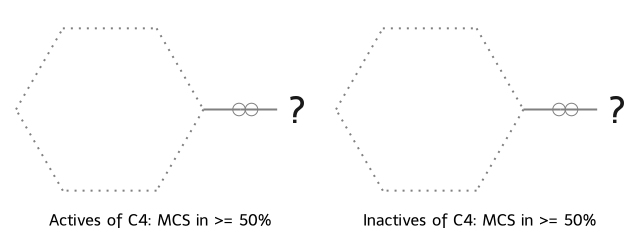

In [ ]:
best_cluster = int(res['active_%'].reset_index(drop=True).idxmax()) + 1
print(f'Most active cluster: C{best_cluster} ({res.iloc[best_cluster - 1]["active_%"]:.0f}% active)')

rows = []
for group, cls in (('Active', 1), ('Inactive', 0)):
    sub = list(df.loc[(df.cluster == best_cluster) & (df.Class == cls), 'mol'])
    for threshold in (0.8, 0.5):
        r = mcs(sub, threshold)
        rows.append(dict(group=f'{group} in C{best_cluster}', n=len(sub), present_in=f'{threshold:.0%}',
                         n_atoms=r.numAtoms, SMARTS=(r.smartsString or '(none)')[:60] + '...'))
display(pd.DataFrame(rows))

queries, legends = [], []
for group, cls in (('Actives', 1), ('Inactives', 0)):
    r = mcs(list(df.loc[(df.cluster == best_cluster) & (df.Class == cls), 'mol']), 0.5)
    queries.append(Chem.MolFromSmarts(r.smartsString)); legends.append(f'{group} of C{best_cluster}: MCS in >= 50%')
Draw.MolsToGridImage(queries, molsPerRow=2, subImgSize=(320, 240), legends=legends)

### 7.2 Enrichment of known pharmacophore fragments

Binary features are searched in the **ionised** form (`mol_ion`), because "protonated amine" and "carboxylate" are
exactly the ionisation states that matter for hERG. For each fragment we compare the fraction of actives and inactives containing it
(Fisher exact test, Benjamini–Hochberg corrected over the panel; the odds ratio is computed with a 0.5 continuity correction).

In [ ]:
panel = {
    'protonated amine  [NX4+]':             '[NX4+]',
    'protonated tertiary amine [NX4+;H1]':  '[NX4+;H1]',
    'carboxylic acid / carboxylate':        '[CX3](=O)[OX2H1,OX1-]',
    'phenyl ring':                          'c1ccccc1',
    'aryl fluoride':                        'cF',
    'aryl chloride':                        'cCl',
    'piperidine ring':                      '[#7]1CCCCC1',
    'piperazine ring':                      '[#7]1CC[#7]CC1',
    'nitrile':                              'C#N',
    'sulfonamide':                          'S(=O)(=O)[NX3]',
    'amide':                                'C(=O)[NX3]',
    'ester':                                '[CX3](=O)[OX2][#6]',
    'aliphatic hydroxyl':                   '[CX4][OX2H]',
    'phenol':                               'c[OX2H]',
    'aryl ether':                           'c[OX2][CX4]',
}

mol_ion = list(df['mol_ion'])
features = pd.DataFrame({name: [m.HasSubstructMatch(Chem.MolFromSmarts(s)) for m in mol_ion]
                         for name, s in panel.items()})
# the classical hERG pharmacophore: a basic centre together with >= 2 aromatic rings
features['basic N + >=2 aromatic rings'] = features['protonated amine  [NX4+]'] & (desc['NumAromaticRings'] >= 2)

def enrichment(features, y):
    rows = []
    for name in features:
        h = features[name].to_numpy()
        a, b = int((h & (y == 1)).sum()), int((h & (y == 0)).sum())
        c, d_ = int((~h & (y == 1)).sum()), int((~h & (y == 0)).sum())
        odds = ((a + .5) * (d_ + .5)) / ((b + .5) * (c + .5))
        rows.append(dict(fragment=name, n=a + b, pct_active=100 * a / (a + c), pct_inactive=100 * b / (b + d_),
                         odds_ratio=odds, p=stats.fisher_exact([[a, b], [c, d_]])[1]))
    out = pd.DataFrame(rows).set_index('fragment')
    out['p_BH'] = stats.false_discovery_control(out['p'])
    return out.sort_values('odds_ratio', ascending=False)

enr = enrichment(features, y)
display(enr.round({'pct_active': 1, 'pct_inactive': 1, 'odds_ratio': 2, 'p': 6, 'p_BH': 6}))

,n,pct_active,pct_inactive,odds_ratio,p,p_BH
fragment,,,,,,
basic N + >=2 aromatic rings,193,68.0,15.4,11.52,0.000000,0.000000
phenyl ring,469,96.6,76.5,8.09,0.000000,0.000000
protonated amine [NX4+],304,82.8,38.1,7.70,0.000000,0.000000
nitrile,38,12.8,3.4,4.13,0.000036,0.000072
piperidine ring,112,35.0,11.5,4.12,0.000000,0.000000
protonated tertiary amine [NX4+;H1],195,54.7,23.5,3.90,0.000000,0.000000
aryl fluoride,56,17.2,5.9,3.30,0.000030,0.000068
piperazine ring,39,11.3,4.5,2.69,0.003079,0.005474
amide,166,33.5,27.5,1.33,0.148868,0.192985


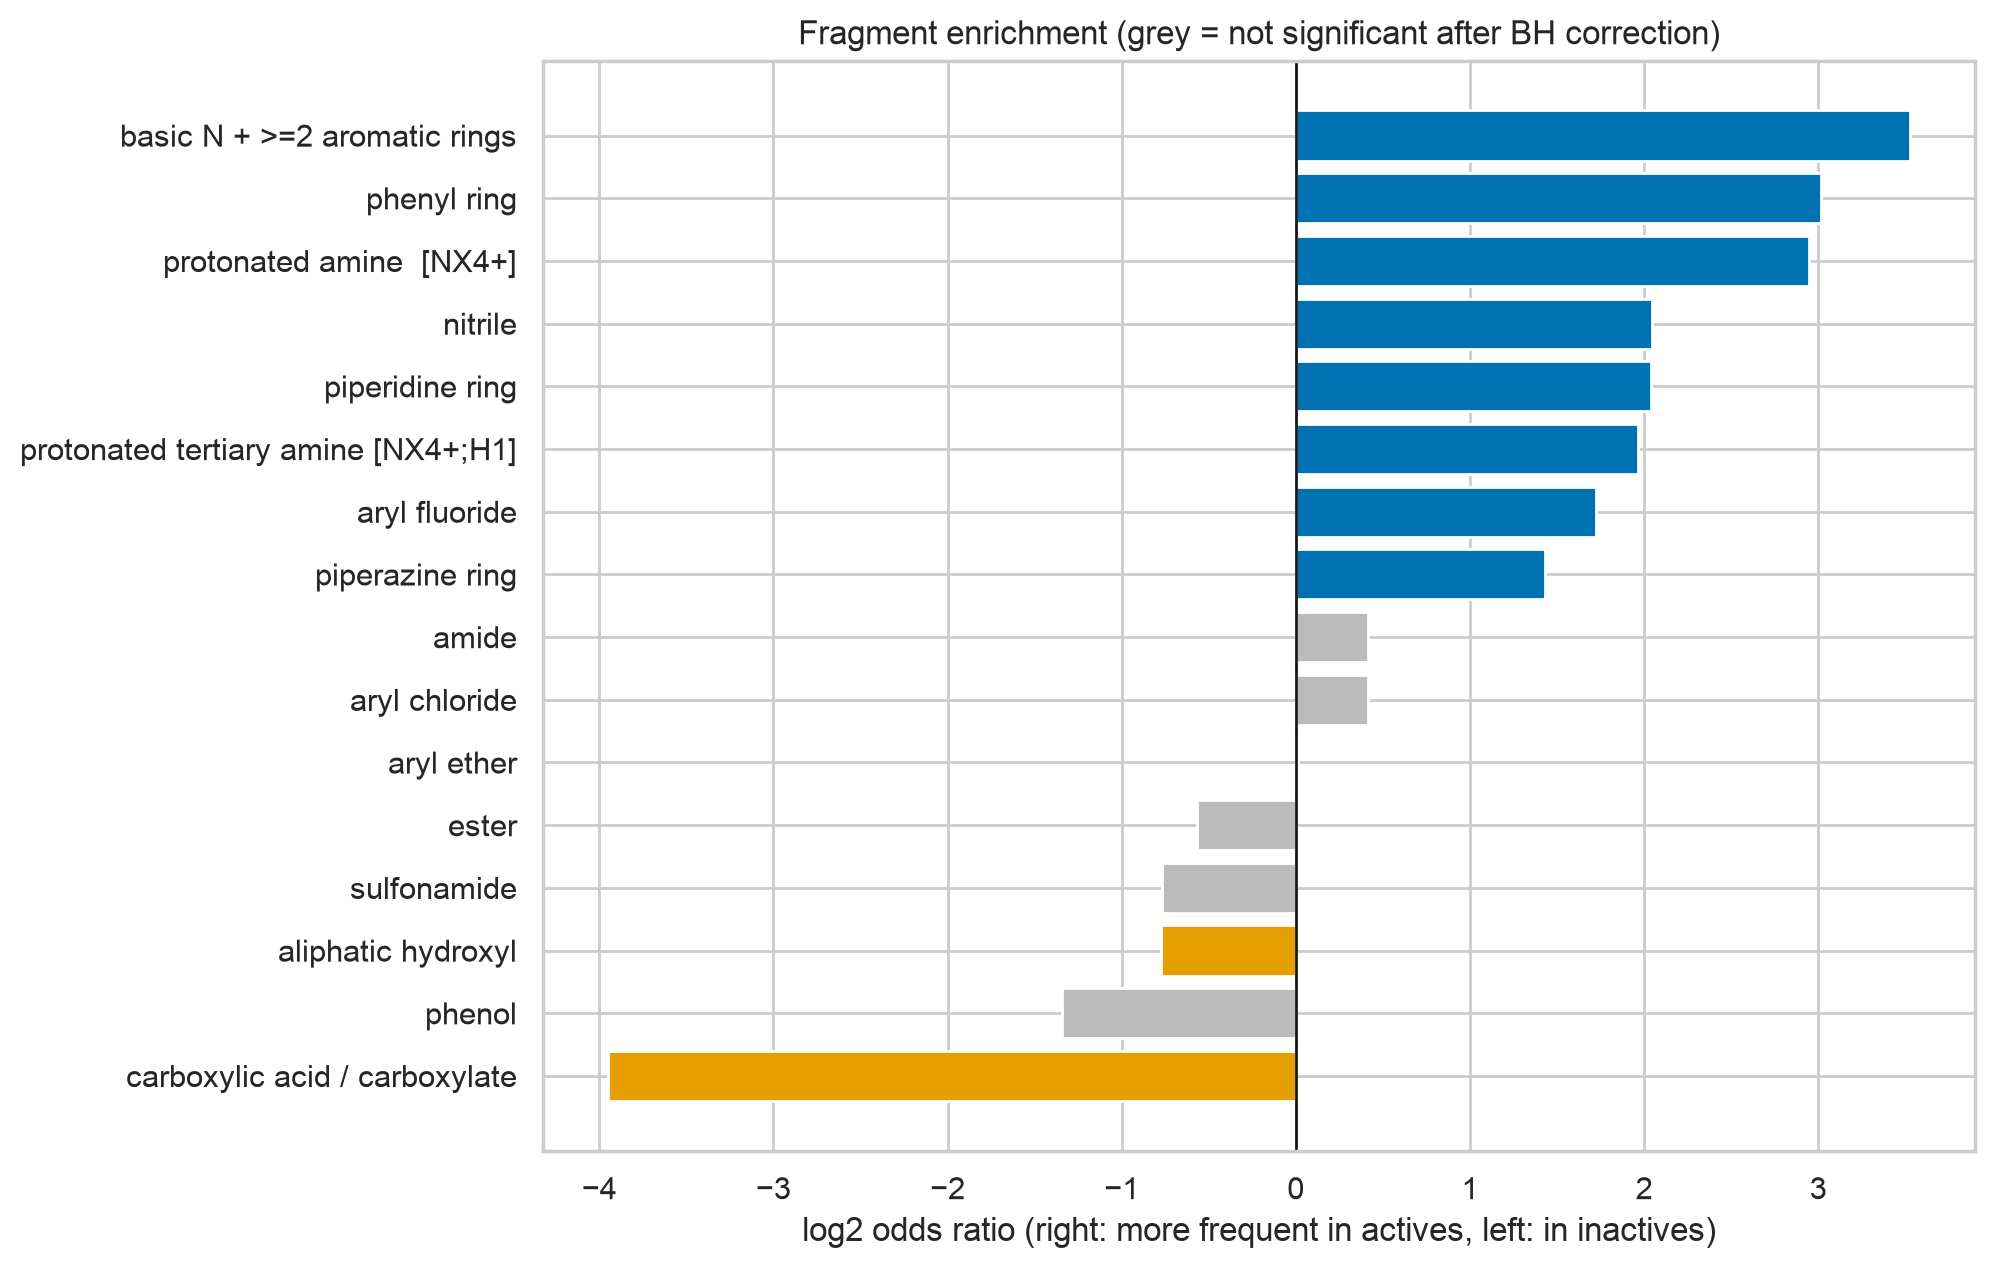

In [ ]:
plot_df = enr.copy()
plot_df['log2_OR'] = np.log2(plot_df['odds_ratio'])
plot_df = plot_df.sort_values('log2_OR')
colors = np.where(plot_df['p_BH'] < 0.05, np.where(plot_df['log2_OR'] > 0, CLASS_COLORS['Active'], CLASS_COLORS['Inactive']), '#bbbbbb')
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(plot_df.index, plot_df['log2_OR'], color=colors)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel('log2 odds ratio (right: more frequent in actives, left: in inactives)')
ax.set_title('Fragment enrichment (grey = not significant after BH correction)')
plt.tight_layout(); plt.show()

### 7.3 Where do the fragments live? Prevalence per cluster

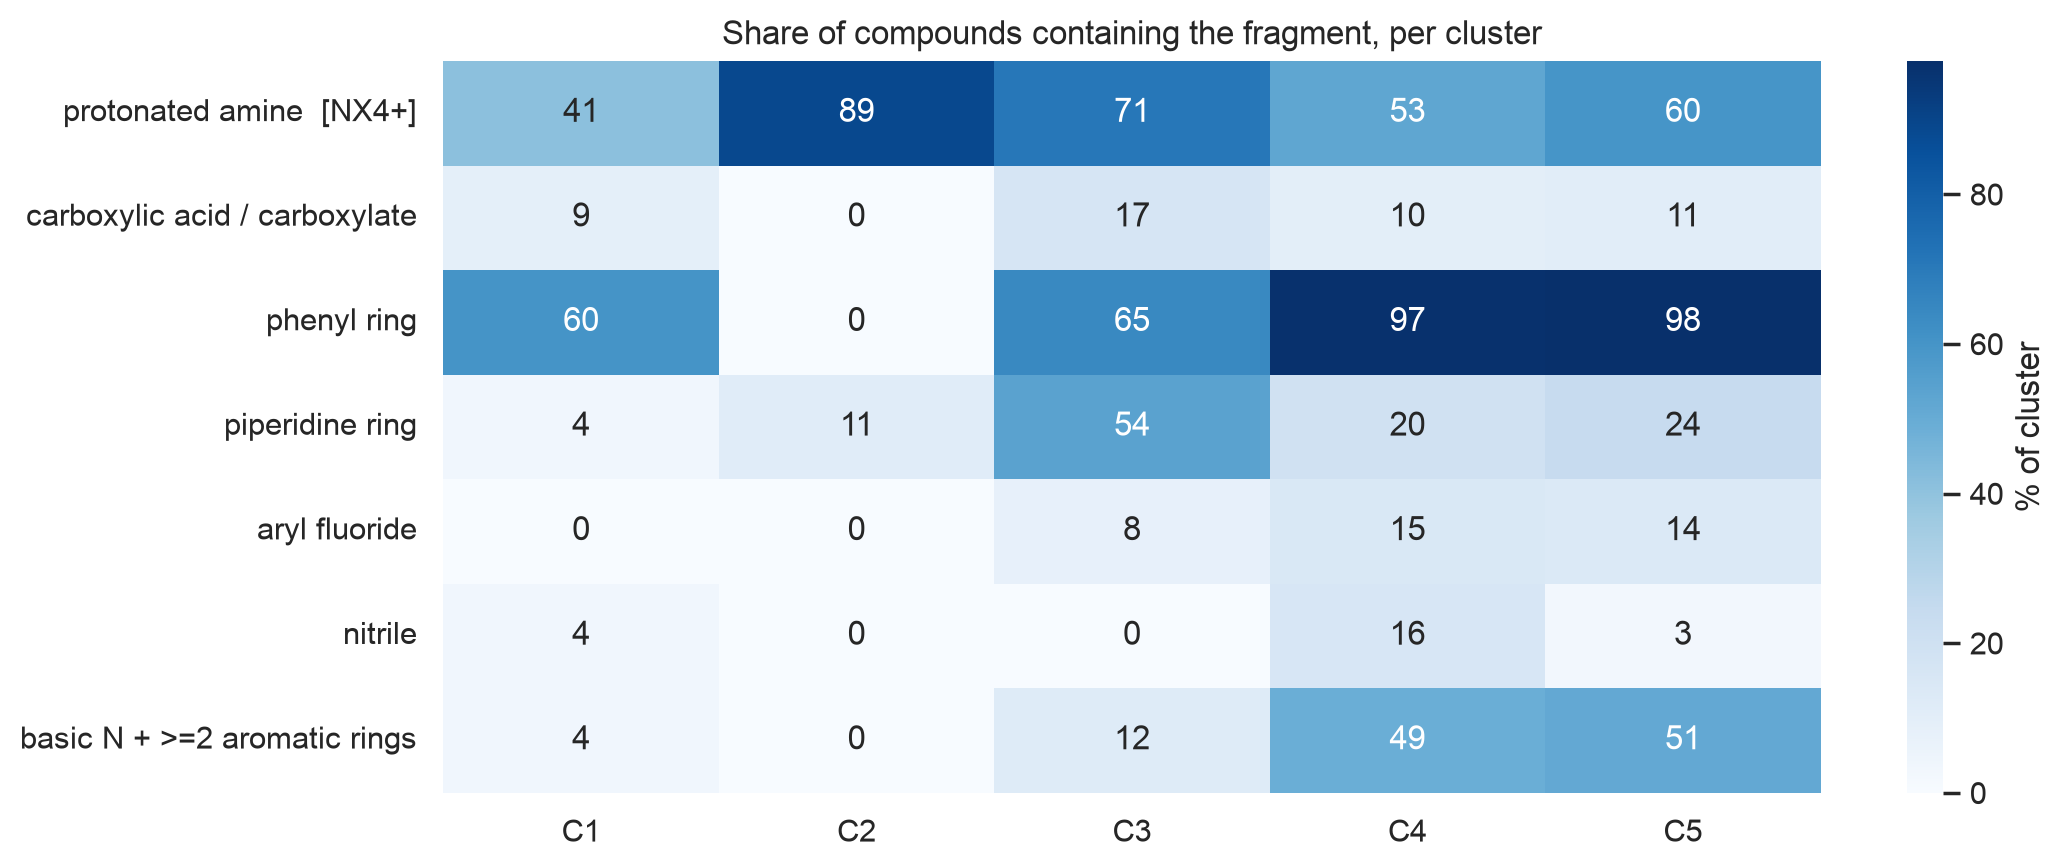

In [ ]:
prev = features.groupby(df['cluster'].to_numpy()).mean().mul(100)
prev.index = [f'C{c}' for c in prev.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(prev[['protonated amine  [NX4+]', 'carboxylic acid / carboxylate', 'phenyl ring', 'piperidine ring',
                  'aryl fluoride', 'nitrile', 'basic N + >=2 aromatic rings']].T,
            annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of cluster'}, ax=ax)
ax.set_title('Share of compounds containing the fragment, per cluster'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

### 7.4 Data-driven scan of Morgan fragments

246 fragments tested, 104 significant after BH correction
Fragments most enriched in ACTIVE compounds (blue = central atom, yellow = aromatic atoms, grey = aliphatic atoms; * = attachment):


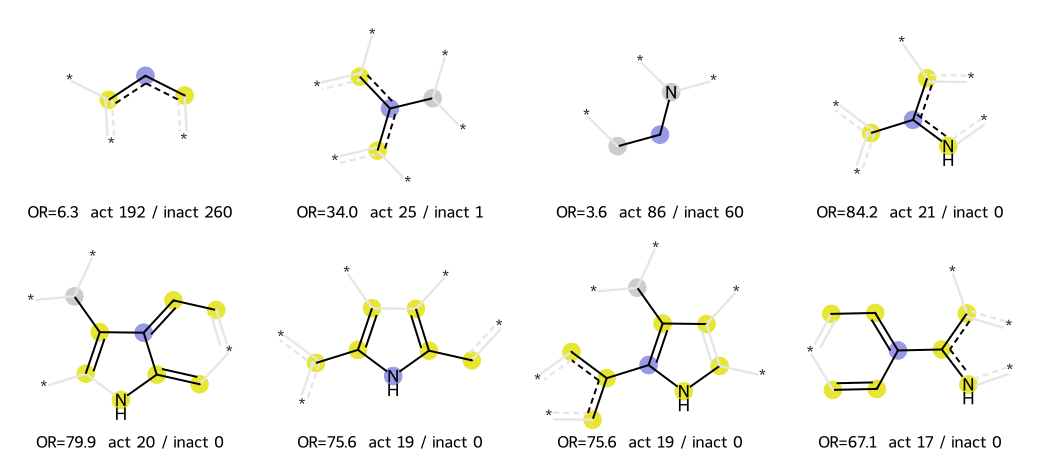

In [ ]:
# Every radius<=2 Morgan environment present in >= 15 compounds is tested for enrichment (Fisher exact test)
bit_info, bit_sets = [], []
for m in df['mol']:
    bi = {}
    rdMolDescriptors.GetMorganFingerprint(m, 2, bitInfo=bi)
    bit_info.append(bi); bit_sets.append(set(bi))

from collections import Counter
counts = Counter(b for s in bit_sets for b in s)
rows = []
for bit, cnt in counts.items():
    if cnt < 15:
        continue
    h = np.array([bit in s for s in bit_sets])
    a, b = int((h & (y == 1)).sum()), int((h & (y == 0)).sum())
    c, d_ = int((~h & (y == 1)).sum()), int((~h & (y == 0)).sum())
    first = next(i for i, s in enumerate(bit_sets) if bit in s)
    radius = min(r for _, r in bit_info[first][bit])
    rows.append(dict(bit=bit, n=cnt, n_active=a, n_inactive=b, odds_ratio=((a + .5) * (d_ + .5)) / ((b + .5) * (c + .5)),
                     p=stats.fisher_exact([[a, b], [c, d_]])[1], radius=radius,
                     members=h.tobytes(), example=first))
frag = pd.DataFrame(rows)
frag['p_BH'] = stats.false_discovery_control(frag['p'])
print(f'{len(frag)} fragments tested, {(frag.p_BH < 0.05).sum()} significant after BH correction')

# keep one fragment per distinct set of compounds (many overlapping environments describe the same molecules)
# and ignore single-atom environments (radius 0)
sel = (frag[(frag.p_BH < 0.05) & (frag.radius >= 1)].sort_values('p').drop_duplicates('members'))
top_act = sel[sel.odds_ratio > 1].head(8)
top_ina = sel[sel.odds_ratio < 1].head(8)

def show_bits(table, title):
    items = [(df.loc[r.example, 'mol'], int(r.bit), bit_info[r.example]) for r in table.itertuples()]
    legends = [f'OR={r.odds_ratio:.1f}  act {r.n_active} / inact {r.n_inactive}' for r in table.itertuples()]
    print(title)
    return Draw.DrawMorganBits(items, molsPerRow=4, subImgSize=(260, 230), legends=legends, useSVG=False)

show_bits(top_act, 'Fragments most enriched in ACTIVE compounds (blue = central atom, yellow = aromatic atoms, grey = aliphatic atoms; * = attachment):')

Fragments most enriched in INACTIVE compounds (highlighted atoms = the fragment):


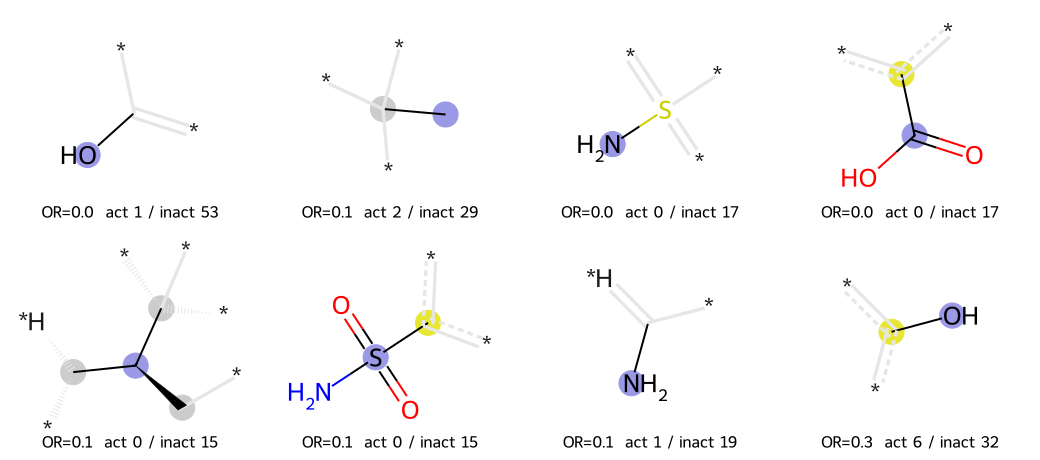

In [ ]:
show_bits(top_ina, 'Fragments most enriched in INACTIVE compounds (highlighted atoms = the fragment):')

Inside C4 both the actives and the inactives share the same thing: a **benzene ring** (plus, for 50% of them, one attached carbon). The MCS therefore
does not discriminate between actives and inactives either.

**Interpretation of the fragment analysis.**

* **Characteristic of actives:** protonated (basic) amines, especially tertiary amines and piperidine/piperazine rings; aromatic rings
  (phenyl, aryl fluorides) and nitriles; the data-driven scan adds indole/benzimidazole-type `[nH]` aromatic rings
  (about 20 actives and no inactive for several overlapping environments). The combination "basic nitrogen + at least two aromatic rings" is the
  classical hERG pharmacophore (a cation that interacts with the pore's aromatic residues Tyr652/Phe656, flanked by hydrophobic groups).
* **Characteristic of inactives:** carboxylic acids/carboxylates (only 1% of actives against 16% of inactives, OR ≈ 0.06; anionic molecules are
  strongly depleted among blockers) and polar hydrogen-bonding groups: aliphatic hydroxyls (significant), phenols (a trend that
  does not survive the multiple-testing correction), and in the fragment scan primary sulfonamides, primary amines and hydroxyls.
* There is no *single* scaffold that defines the actives (empty MCS, §7.1): the activity is determined by a **combination of
  features** (basic centre + lipophilic aromatic groups), not by a common core.

## 8. The same analysis in R

The R half uses `FactoMineR`/`factoextra` for PCA, `hclust` and `cutree` for hierarchical clustering and `cluster::silhouette` to check
whether the clustering is reliable. It is run from this notebook with `rpy2` (the `%%R` cell magic), exactly as in the course notebook.

* The input is the **same standardised descriptor matrix** (`Z_df`, 560 × 43) and the same labels, so the results are comparable with §3–§6.
* Requirements: R with the packages `cluster`, `FactoMineR`, `factoextra` and the Python package `rpy2`. On Google Colab both are available;
  the next cell installs the two R packages if they are missing (this can take a few minutes the first time).

In [ ]:
# Objects handed over to R
desc_scaled_df = Z_df                      # 560 x 43 standardised descriptors
outcome = df['Class']                      # 0 / 1 labels (pandas Series)
logp = df['logP']                          # Crippen logP of the neutral molecules

In [ ]:
import rpy2.rinterface
%reload_ext rpy2.ipython

In [ ]:
%%R
pkgs <- c("FactoMineR", "factoextra")
missing_pkgs <- pkgs[!(pkgs %in% installed.packages()[, "Package"])]
if (length(missing_pkgs)) install.packages(missing_pkgs, repos = "https://cloud.r-project.org")
suppressPackageStartupMessages({
  library(FactoMineR)   # PCA
  library(factoextra)   # PCA / dendrogram plots
  library(cluster)      # silhouette
})
cat("R", R.version.string, "\n")

### 8.1 PCA with FactoMineR

In [ ]:
%%R -i desc_scaled_df -i outcome -w 1000 -h 450
res_pca <- PCA(desc_scaled_df, scale.unit = TRUE, graph = FALSE)
outcome_f <- factor(outcome, levels = c(0, 1), labels = c("Inactive", "Active"))

print(round(res_pca$eig[1:8, ], 2))                       # eigenvalues and % of variance
print(fviz_eig(res_pca, addlabels = TRUE, ylim = c(0, 50)))

In [ ]:
%%R -w 1000 -h 500
p1 <- fviz_pca_ind(res_pca, geom = "point", col.ind = outcome_f,
                   palette = c("#E69F00", "#0072B2"), addEllipses = TRUE,
                   legend.title = "hERG class", title = "Compounds in the PC1-PC2 plane")
p2 <- fviz_pca_var(res_pca, col.var = "contrib", select.var = list(contrib = 15),
                   repel = TRUE, title = "15 descriptors contributing most to PC1-PC2")
gridExtra::grid.arrange(p1, p2, ncol = 2)

### 8.2 Hierarchical clustering: `dist`, `hclust`, `cutree`

The same four linkage methods as in the Python half. `ward.D2` is the R name of the algorithm implemented by scikit-learn / SciPy
as `ward`.

In [ ]:
%%R -w 1000 -h 700
dist_matrix <- dist(desc_scaled_df, method = "euclidean")

hc <- list(complete = hclust(dist_matrix, method = "complete"),
           ward     = hclust(dist_matrix, method = "ward.D2"),
           average  = hclust(dist_matrix, method = "average"),
           single   = hclust(dist_matrix, method = "single"))

par(mfrow = c(2, 2))
for (nm in names(hc)) plot(hc[[nm]], hang = -1, labels = FALSE, main = paste("Linkage:", nm), xlab = "", sub = "")
par(mfrow = c(1, 1))

# cophenetic correlation: how well does each tree preserve the original distances?
print(round(sapply(hc, function(h) cor(dist_matrix, cophenetic(h))), 3))

In [ ]:
%%R -w 1000 -h 500
K <- 5                                   # same number of clusters as in Python (see Python section 4.4)
hclust_complete <- hc$complete
hclust_ward     <- hc$ward

cut_complete <- cutree(hclust_complete, k = K)
cut_ward     <- cutree(hclust_ward,     k = K)

cat("Cluster sizes, complete linkage:\n"); print(table(cut_complete))
cat("Cluster sizes, Ward.D2:\n");          print(table(cut_ward))

plot(hclust_ward, hang = -1, labels = FALSE, main = paste("Ward.D2, cut at K =", K), xlab = "", sub = "")
rect.hclust(hclust_ward, k = K, border = 2:(K + 1))

### 8.3 Is the clustering reliable? Silhouette analysis

`silhouette()` returns for each compound the width *s(i)* ∈ [−1, 1]: close to 1 = well inside its cluster, near 0 = on the border
between two clusters, negative = probably in the wrong cluster. The average width summarises the whole clustering
(≳ 0.5 reasonable structure, ≲ 0.25 no substantial structure).

In [ ]:
%%R -w 1000 -h 600
# check if the clustering is reliable
sil_complete <- silhouette(cut_complete, dist = dist_matrix)
plot(sil_complete, main = "Silhouette plot - complete linkage", col = 2:(K + 1), border = NA)

sil_ward <- silhouette(cut_ward, dist = dist_matrix)
plot(sil_ward, main = "Silhouette plot - Ward.D2", col = 2:(K + 1), border = NA)

cat("Average silhouette width: complete =", round(mean(sil_complete[, "sil_width"]), 3),
    "| Ward.D2 =", round(mean(sil_ward[, "sil_width"]), 3), "\n")
cat("Share of compounds with negative width: complete =", round(mean(sil_complete[, "sil_width"] < 0), 3),
    "| Ward.D2 =", round(mean(sil_ward[, "sil_width"] < 0), 3), "\n")

In [ ]:
%%R -w 900 -h 450
# average silhouette width as a function of k, for the four linkages
ks <- 2:12
avg_sil <- sapply(hc, function(h) sapply(ks, function(k) mean(silhouette(cutree(h, k), dist_matrix)[, "sil_width"])))
rownames(avg_sil) <- ks
print(round(avg_sil, 3))

matplot(ks, avg_sil, type = "b", pch = 1:4, lty = 1, col = 1:4, xlab = "number of clusters k",
        ylab = "average silhouette width", main = "Silhouette vs k (R)")
legend("topright", legend = colnames(avg_sil), col = 1:4, pch = 1:4, lty = 1)

### 8.4 Active percentage and logP per cluster in R

In [ ]:
%%R -i logp -w 1000 -h 450
tab <- table(cluster = cut_ward, outcome = outcome_f)
active_pct <- round(100 * tab[, "Active"] / rowSums(tab), 1)
print(cbind(tab, n = rowSums(tab), active_pct = active_pct))
overall <- round(100 * mean(outcome_f == "Active"), 1)
cat("Overall active percentage:", overall, "%\n")
print(chisq.test(tab, simulate.p.value = TRUE, B = 10000))

par(mfrow = c(1, 3))
barplot(active_pct, col = 2:(K + 1), ylim = c(0, 100), xlab = "cluster", ylab = "% active", main = "Active % per cluster")
abline(h = overall, lty = 2, col = "red")
boxplot(logp ~ outcome_f, col = c("#E69F00", "#0072B2"), ylab = "logP", xlab = "", main = "logP: inactive vs active")
boxplot(logp ~ cut_ward, col = 2:(K + 1), ylab = "logP", xlab = "cluster", main = "logP per cluster")
par(mfrow = c(1, 1))

print(wilcox.test(logp ~ outcome_f))
print(kruskal.test(logp ~ factor(cut_ward)))

### 8.5 Do R and Python agree?

Both halves use Ward's criterion on the same standardised matrix, so the partitions should be (nearly) identical up to the
numbering of the clusters. The adjusted Rand index (ARI) is 1 for identical partitions and about 0 for unrelated ones.

In [ ]:
%%R -o cut_ward -o cut_complete
invisible(NULL)     # hand the cluster vectors back to Python

In [ ]:
try:
    r_ward = np.asarray(cut_ward).ravel().astype(int)
    r_complete = np.asarray(cut_complete).ravel().astype(int)
    print('ARI  R Ward.D2  vs Python Ward :', round(adjusted_rand_score(r_ward, df['cluster']), 3))
    print('ARI  R complete vs Python complete (k=5):',
          round(adjusted_rand_score(r_complete, labels_store[('complete', 'descriptors', K)]), 3))
    display(pd.crosstab(pd.Series(r_ward, name='R cutree (Ward.D2)'), df['cluster'].rename('Python cluster')))
except NameError:
    print('Run the R cells above first: cut_ward / cut_complete come from R.')

## 9. Conclusions

**Data.** 562 compounds (36% hERG blockers). 311 SMILES had protonated amines written without hydrogens (read as radicals by RDKit); these were
repaired, sulfonyl groups were normalised and 2 duplicate structures removed (560 compounds). The swapped `MolLogP`/`MolMR` entries of the course
descriptor dictionary were corrected.

**Clustering (task 1).** Seven method/representation combinations were compared. Fingerprint (Tanimoto) clustering and Butina fail on this very diverse
set of drugs (silhouette ≈ 0.03, mostly singletons); single/average linkage only isolate outliers. **Ward hierarchical clustering on the 43 standardised
descriptors** was chosen: balanced clusters for every *k*, a silhouette within 0.03 of k-means, a deterministic nested tree, and an identical algorithm in R.
*K* = 5 was chosen from the longest plateau of the dendrogram. The structure is weak (average silhouette 0.16, moderate stability): the clusters are regions of a
continuum of molecular size, polarity and aromaticity.

**Active percentage (task 2).** 36% overall; 12% in the small polar cluster C1, 27% in C3, **49% in C4 and 47% in C5** (large/compact lipophilic aromatic
molecules); C2 (9 macrolides) has too few compounds to conclude. The association is highly significant (p ≈ 10⁻¹²).

**logP (task 3).** Actives are more lipophilic (median 3.96 vs 2.52, p ≈ 10⁻¹⁷, AUC 0.72). Within clusters the difference is smaller (0.6–0.9 log units, absent in C3):
part of the global effect comes from differences *between* clusters.

**Sub-structures (task 4).** No common core exists (empty MCS for both groups). Actives are enriched in **protonated amines (OR ≈ 8), piperidines, aromatic rings,
aryl fluorides and nitriles**; the combination *basic N + ≥ 2 aromatic rings* is present in 68% of the actives and 15% of the inactives (OR ≈ 12). Inactives are
enriched in **carboxylic acids (1% vs 16%)** and polar H-bonding groups. This agrees with the classical hERG pharmacophore.

**Limitations.** Class labels come from several literature sources (23 references) with possibly different thresholds and assay conditions; logP is a
computed (Crippen) value; the clustering is unsupervised and descriptive and should not be used as a predictive model; the enrichment tests are
univariate and the fragments are correlated with one another.